In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import squarify
import seaborn as sns

pastel_colors = ["#A8DADC", "#FFD6A5", "#BDE0FE", "#FFC8DD", "#CDB4DB", "#D8F3DC"]
highlight_color = "#FF6B6B"

In [2]:
# -- Pandas display options (from marketing notebook) --
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams['font.size'] = 12
path_dataClean =  "dataCleaned/"

In [3]:
# Khách hàng và Doanh thu
orders =  pd.read_csv(path_dataClean + "cleaned_orders.csv")
payments =  pd.read_csv(path_dataClean + "cleaned_payments.csv")
customers =  pd.read_csv(path_dataClean + "customers_cleaned.csv")
geo =  pd.read_csv(path_dataClean + "geography_cleaned.csv")
sales     = pd.read_csv(path_dataClean + 'sale_cleaned.csv')


print("orders   :", orders.shape)
print("payments :", payments.shape)
print("customers:", customers.shape)
print("geo      :", geo.shape)
print("sales    :", sales.shape)


orders   : (646945, 8)
payments : (646945, 4)
customers: (121930, 7)
geo      : (39948, 5)
sales    : (3833, 3)


### Phần 1
### Mục tiêu

1. Tìm số lượng đơn hàng và doanh thu biến động như nào qua các mốc thời gian. Khi nào thì đạt đỉnh
2. Nhóm khách hàng đóng góp chính vào trong khối lượng mà nhóm khách hàng đó đã chi cho doanh nghiệp(Phân theo độ tuổi, giới tính và khu vực)
3. Doanh thu theo thời gian tìm ra thông tin về tháng có Doanh thu cao nhất và thấp nhất.
4. Hình thức mang lại rủi ro cao nhất, tỷ lệ hoàn hàng và hủy đơn ở đâu
5. Nhóm khách hàng nào có AOV cao nhất và kênh truyền thông nào mang khách hàng đến doanh nghiệp
6. Tìm kiếm nhóm khách hàng mang lại doanh thu cao nhất. Nhóm khách hàng có nguy cơ rời bỏ cao nhất

In [5]:
df1 = orders[orders['order_status'] == 'delivered'].copy()
df1["order_date"] = pd.to_datetime(df1["order_date"])
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 516716 entries, 0 to 646944
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   order_id        516716 non-null  int64         
 1   order_date      516716 non-null  datetime64[ns]
 2   customer_id     516716 non-null  int64         
 3   zip             516716 non-null  int64         
 4   order_status    516716 non-null  object        
 5   payment_method  516716 non-null  object        
 6   device_type     516716 non-null  object        
 7   order_source    516716 non-null  object        
dtypes: datetime64[ns](1), int64(3), object(4)
memory usage: 35.5+ MB


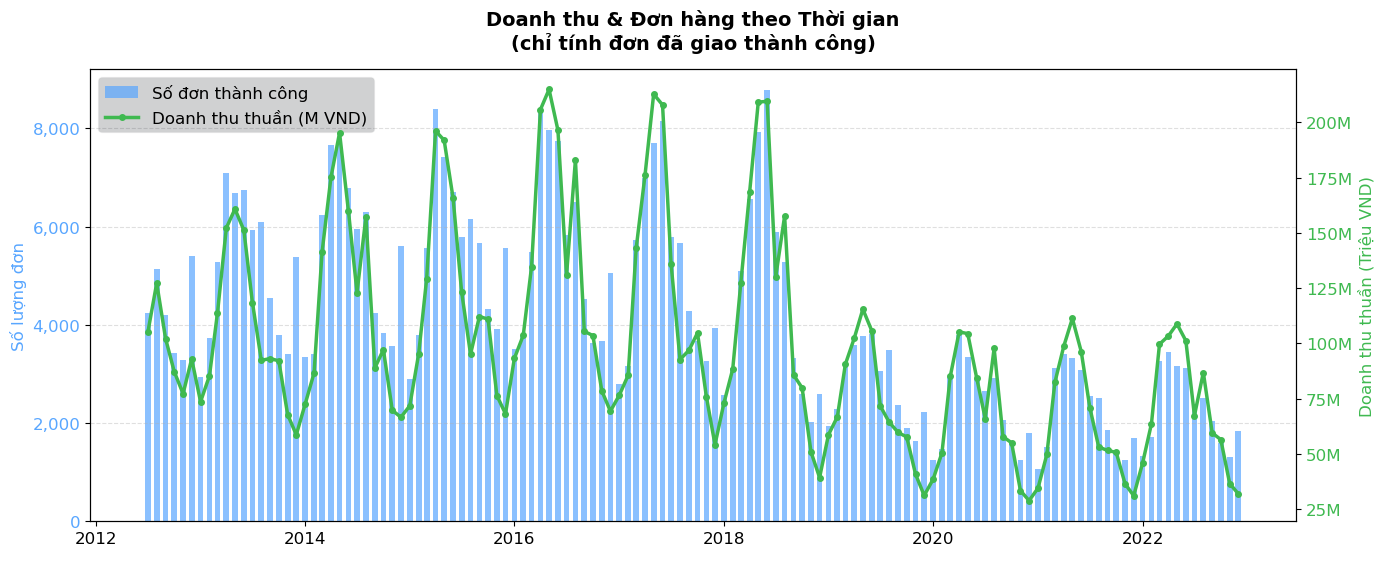

In [6]:
# ── Chart 1: Revenue & Orders over Time (delivered only) ──
df1 = orders[orders['order_status'] == 'delivered'].copy()
df1["order_date"] = pd.to_datetime(df1["order_date"])
df1 = df1.merge(payments[['order_id','payment_value']], on='order_id', how='left')
df1['month'] = df1['order_date'].dt.to_period('M')

monthly = df1.groupby('month').agg(
    num_orders    = ('order_id',      'count'),
    net_revenue   = ('payment_value', 'sum')
).reset_index()
monthly['month_dt'] = monthly['month'].dt.to_timestamp()

fig, ax1 = plt.subplots(figsize=(14, 6))

# Bar – order count
bars = ax1.bar(monthly['month_dt'], monthly['num_orders'],
               width=20, color='#58A6FF', alpha=0.7, label='Số đơn thành công')
ax1.set_xlabel('Thời gian (Tháng/Năm)', fontsize=12, labelpad=8, color = "white")
ax1.set_ylabel('Số lượng đơn', color='#58A6FF', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#58A6FF')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# Line – revenue
ax2 = ax1.twinx()
ax2.set_facecolor('#161B22')
ax2.plot(monthly['month_dt'], monthly['net_revenue'] / 1e6,
         color='#3FB950', linewidth=2.5, marker='o', markersize=4, label='Doanh thu thuần (M VND)')
ax2.set_ylabel('Doanh thu thuần (Triệu VND)', color='#3FB950', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#3FB950')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}M'))

ax1.grid(axis='y', linestyle='--', alpha=0.4)
plt.title('Doanh thu & Đơn hàng theo Thời gian\n(chỉ tính đơn đã giao thành công)',
          fontsize=14, fontweight='bold', pad=14)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, loc='upper left', framealpha=0.2, facecolor='#161B22')

plt.tight_layout()
plt.show()


**Đánh giá**

- **Tăng trưởng dài hạn:** Hoạt động kinh doanh ghi nhận sự tăng trưởng liên tục về mặt quy mô kể từ khi bắt đầu vào **tháng 07/2012**.
- **Đỉnh cao giao dịch:** Lượng đơn hàng giao thành công (Delivered) và Doanh thu thực nhận (Net Revenue) duy trì đà tăng ấn tượng và tạo đỉnh vào **tháng 05/2016** với mức doanh thu đạt **~215 tỷ VND** / tháng.
- **Tính mùa vụ:** Có thể quan sát thấy những đợt tăng vọt chu kỳ vào các dịp cuối năm, cho thấy nền tảng đang tận dụng tốt các đợt bùng nổ nhu cầu mua sắm.
- **Kết luận:** Nền tảng đã mở rộng thị phần rất tốt và thu hút được lượng lớn giao dịch qua các năm. Tuy nhiên, đà tăng trưởng có dấu hiệu đi ngang và chững lại ở giai đoạn sau, đòi hỏi những chiến lược tối ưu thay vì chỉ mở rộng ròng.


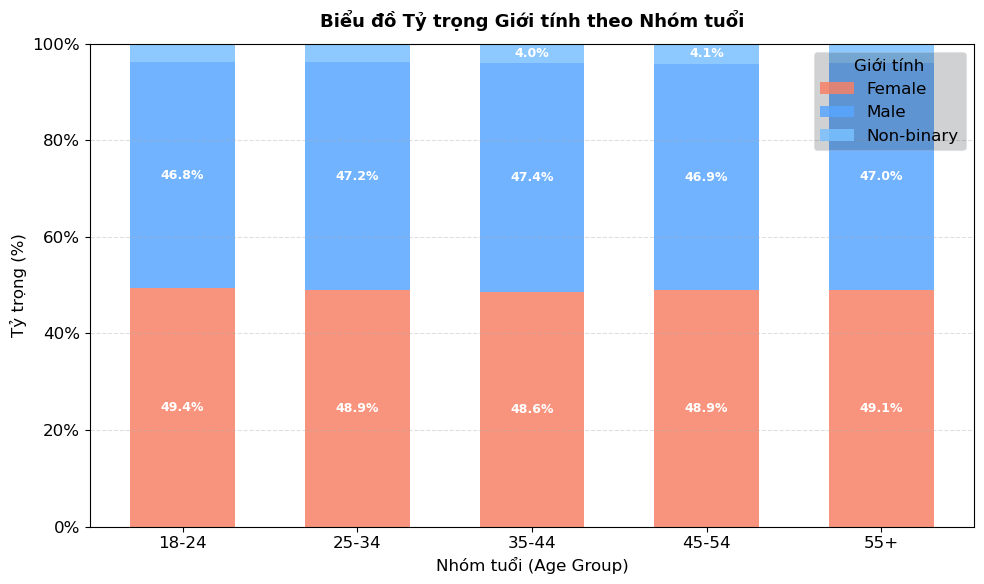

gender,Female,Male,Non-binary
age_group,,,
18-24,49.3515,46.7692,3.8793
25-34,48.9379,47.2098,3.8523
35-44,48.5746,47.3966,4.0288
45-54,48.9082,46.9489,4.1429
55+,49.1046,46.9867,3.9087


In [8]:
# ── Chart 2: 100% Stacked Bar – Age Group × Gender ──
AGE_ORDER = ['18-24','25-34','35-44','45-54','55+']

df2 = customers.copy()
df2['age_group'] = pd.Categorical(df2['age_group'], categories=AGE_ORDER, ordered=True)
pivot = df2.groupby(['age_group','gender'])['customer_id'].count().unstack(fill_value=0)
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 6))

colors_gender = {'Male': '#58A6FF', 'Female': '#F78166', 'Other': '#D2A8FF'}
bottom = np.zeros(len(pivot_pct))

for gender in pivot_pct.columns:
    color = colors_gender.get(gender, '#79C0FF')
    vals  = pivot_pct[gender].values
    bars  = ax.bar(pivot_pct.index.astype(str), vals, bottom=bottom,
                   label=gender, color=color, alpha=0.85, width=0.6)
    # Label inside bar if wide enough
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 4:
            ax.text(i, b + v/2, f'{v:.1f}%', ha='center', va='center',
                    fontsize=9, color='white', fontweight='bold')
    bottom += vals

ax.set_ylim(0, 100)
ax.set_ylabel('Tỷ trọng (%)', fontsize=12)
ax.set_xlabel('Nhóm tuổi (Age Group)', fontsize=12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x)}%'))
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(title='Giới tính', loc='upper right', framealpha=0.2, facecolor='#161B22')
plt.title('Biểu đồ Tỷ trọng Giới tính theo Nhóm tuổi',
          fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()
display(pivot_pct)

In [9]:
df2["age_group"].value_counts(normalize=True).reset_index()

,age_group,proportion
0,25-34,0.2981
1,35-44,0.2618
2,45-54,0.1900
3,18-24,0.1397
4,55+,0.1104


**Đánh giá**

- **Độ phủ rộng rãi:** Cấu trúc khách hàng khá đa dạng và cân bằng. Tỷ lệ giới tính **Nữ (48.9%)** và **Nam (47.1%)** phân bổ tương đối đồng đều ở mọi nhóm tuổi, cho thấy tệp sản phẩm phục vụ được nhu cầu đại chúng mà không bị lệch hẳn về một giới tính nào.
- **Lực lượng chủ chốt:** Nhóm tuổi **25-34** là "xương sống" của nền tảng, chiếm tỷ trọng cao nhất với **29.8%** tổng quy mô khách hàng. Kế đó là nhóm 35-44 và 18-24.
- **Kết luận:** Số lượng khách hàng ở nhóm **25-34** đang là nhóm có số lượng đông đảo nhất, những người có thu nhập ổn định và quen thuộc với thương mại điện tử. Đây là nền tảng vững chắc để xây dựng các chiến dịch Marketing cá nhân hóa và chương trình Loyalty.


# Nháp - cus với geo

In [12]:
# dfgeo_copy = geo[["zip", "region"]].copy()
# dfcus_copy = customers.copy()
# dfregioncustomer =  pd.merge(dfcus_copy, dfgeo_copy, on='zip', how='inner')

In [13]:
# dfregioncustomer

In [14]:
# dfregioncustomer_East = dfregioncustomer[dfregioncustomer["region"] == "East"]
# dfregioncustomer_East['age_group'] = pd.Categorical(dfregioncustomer_East['age_group'], categories=AGE_ORDER, ordered=True)
# pivot = dfregioncustomer_East.groupby(['age_group','gender'])['customer_id'].count().unstack(fill_value=0)
# pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

# fig, ax = plt.subplots(figsize=(10, 6))

# colors_gender = {'Male': '#58A6FF', 'Female': '#F78166', 'Other': '#D2A8FF'}
# bottom = np.zeros(len(pivot_pct))

# for gender in pivot_pct.columns:
#     color = colors_gender.get(gender, '#79C0FF')
#     vals  = pivot_pct[gender].values
#     bars  = ax.bar(pivot_pct.index.astype(str), vals, bottom=bottom,
#                    label=gender, color=color, alpha=0.85, width=0.6)
#     # Label inside bar if wide enough
#     for i, (v, b) in enumerate(zip(vals, bottom)):
#         if v > 4:
#             ax.text(i, b + v/2, f'{v:.1f}%', ha='center', va='center',
#                     fontsize=9, color='white', fontweight='bold')
#     bottom += vals

# ax.set_ylim(0, 100)
# ax.set_ylabel('Tỷ trọng (%)', fontsize=12)
# ax.set_xlabel('Nhóm tuổi (Age Group)', fontsize=12)
# ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x)}%'))
# ax.grid(axis='y', linestyle='--', alpha=0.4)
# ax.legend(title='Giới tính', loc='upper right', framealpha=0.2, facecolor='#161B22')
# plt.title('Biểu đồ Tỷ trọng Giới tính theo Nhóm tuổi - Vùng phía đông',
#           fontsize=13, fontweight='bold', pad=12)
# plt.tight_layout()
# plt.show()
# print("Vùng phía đông có:",len(dfregioncustomer_East), "khách hàng")
# (dfregioncustomer_East["age_group"].value_counts().reset_index())

In [15]:
# dfregioncustomer_Central = dfregioncustomer[dfregioncustomer["region"] == "Central"]
# dfregioncustomer_Central['age_group'] = pd.Categorical(dfregioncustomer_Central['age_group'], categories=AGE_ORDER, ordered=True)
# pivot = dfregioncustomer_Central.groupby(['age_group','gender'])['customer_id'].count().unstack(fill_value=0)
# pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

# fig, ax = plt.subplots(figsize=(10, 6))

# colors_gender = {'Male': '#58A6FF', 'Female': '#F78166', 'Other': '#D2A8FF'}
# bottom = np.zeros(len(pivot_pct))

# for gender in pivot_pct.columns:
#     color = colors_gender.get(gender, '#79C0FF')
#     vals  = pivot_pct[gender].values
#     bars  = ax.bar(pivot_pct.index.astype(str), vals, bottom=bottom,
#                    label=gender, color=color, alpha=0.85, width=0.6)
#     # Label inside bar if wide enough
#     for i, (v, b) in enumerate(zip(vals, bottom)):
#         if v > 4:
#             ax.text(i, b + v/2, f'{v:.1f}%', ha='center', va='center',
#                     fontsize=9, color='white', fontweight='bold')
#     bottom += vals

# ax.set_ylim(0, 100)
# ax.set_ylabel('Tỷ trọng (%)', fontsize=12)
# ax.set_xlabel('Nhóm tuổi (Age Group)', fontsize=12)
# ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x)}%'))
# ax.grid(axis='y', linestyle='--', alpha=0.4)
# ax.legend(title='Giới tính', loc='upper right', framealpha=0.2, facecolor='#161B22')
# plt.title('Biểu đồ Tỷ trọng Giới tính theo Nhóm tuổi - Miền trung',
#           fontsize=13, fontweight='bold', pad=12)
# plt.tight_layout()
# plt.show()
# print("Miền trung có:",len(dfregioncustomer_Central), "khách hàng")
# (dfregioncustomer_Central["age_group"].value_counts().reset_index())

# Hết nháp

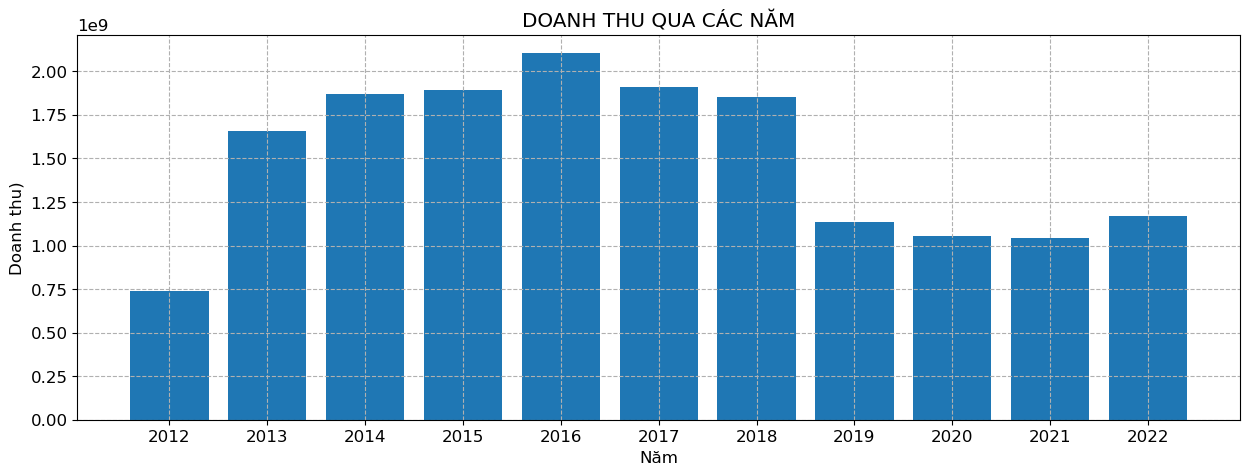

In [17]:
sales['Date'] =  pd.to_datetime(sales['Date'])
sales["year"] = sales['Date'].dt.year

revenuebyYear = sales.groupby(["year"])[["Revenue"]].sum().reset_index().sort_values(by = ['year'])
revenuebyYear[["year", "Revenue"]]
pig, ax =  plt.subplots(figsize=(15, 5))
ax.bar(
    revenuebyYear['year'],
    revenuebyYear['Revenue']
)
ax.set_ylabel('Doanh thu)')
ax.set_xlabel('Năm', fontsize=12)
ax.grid(ls = "--")
ax.set_xticks(range(min(revenuebyYear['year']),max(revenuebyYear['year'])+1))
ax.set_title("DOANH THU QUA CÁC NĂM")    
plt.show()

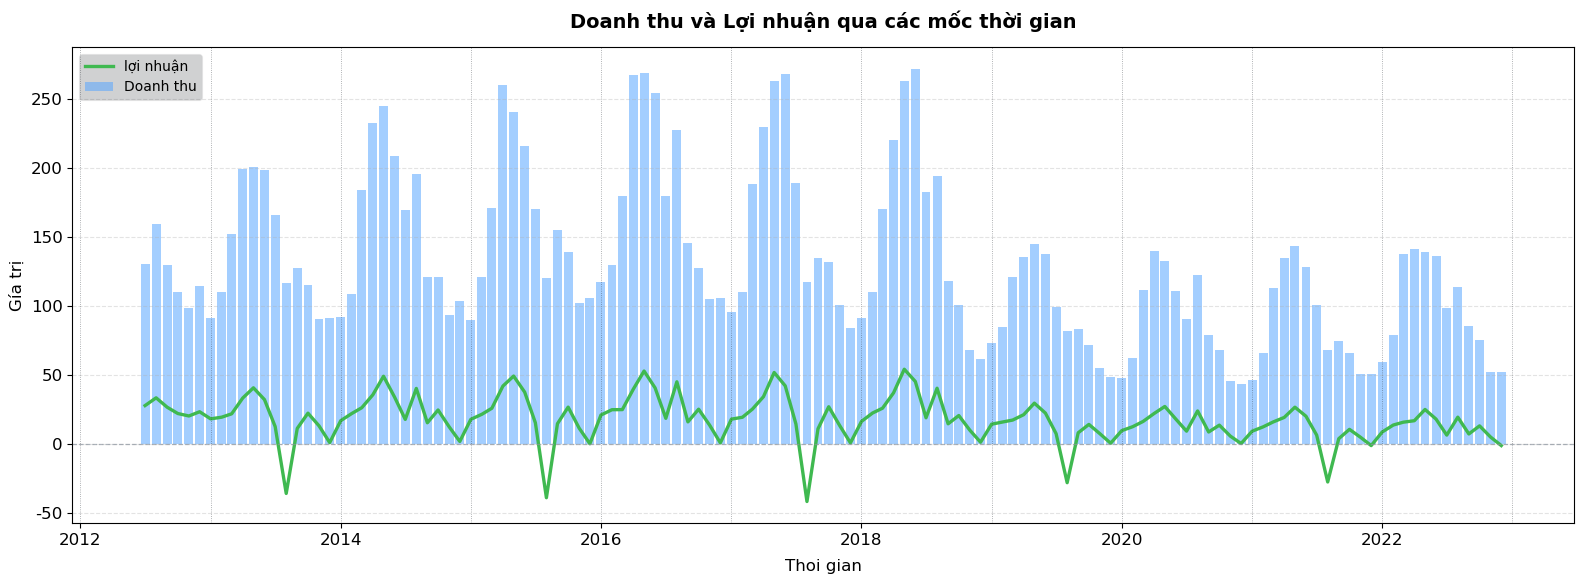

In [18]:
# ── Chart 0: Doanh thu & Loi nhuan theo Thang/Nam (sales.csv) ──
sales['Profit']    = sales['Revenue'] - sales['COGS']
sales['YearMonth'] = sales['Date'].dt.to_period('M')

monthly_s = sales.groupby('YearMonth').agg(
    Revenue = ('Revenue', 'sum'),
    Profit  = ('Profit',  'sum')
).reset_index()
monthly_s['month_dt'] = monthly_s['YearMonth'].dt.to_timestamp()

fig, ax1 = plt.subplots(figsize=(16, 6))

# Revenue bars
ax1.bar(monthly_s['month_dt'], monthly_s['Revenue'] / 1e6,
        width=25, color='#58A6FF', alpha=0.55, label='Doanh thu')

# Profit line
ax1.plot(monthly_s['month_dt'], monthly_s['Profit'] / 1e6,
         color='#3FB950', linewidth=2.4, marker='', label='lợi nhuận')

# Zero baseline
ax1.axhline(y=0, color='#8B949E', linestyle='--', linewidth=0.9, alpha=0.7)

# Year grid lines
for year in range(int(monthly_s['month_dt'].dt.year.min()),
                  int(monthly_s['month_dt'].dt.year.max()) + 2):
    ax1.axvline(pd.Timestamp(f'{year}-01-01'),
                color='#30363D', linestyle=':', linewidth=0.6, alpha=0.5)

ax1.set_xlabel('Thoi gian', fontsize=12, labelpad=8)
ax1.set_ylabel('Gía trị', fontsize=12)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax1.grid(axis='y', linestyle='--', alpha=0.35)
ax1.legend(loc='upper left', framealpha=0.2, facecolor='#161B22', fontsize=10)

plt.title('Doanh thu và Lợi nhuận qua các mốc thời gian',
          fontsize=14, fontweight='bold', pad=14)

plt.tight_layout()
plt.show()


In [19]:
monthly_s[monthly_s["Profit"] < 0]

,YearMonth,Revenue,Profit,month_dt
13,2013-08,"116,271,755.9600","-35,675,935.0400",2013-08-01
37,2015-08,"119,854,986.6300","-38,771,622.4800",2015-08-01
61,2017-08,"117,297,361.7600","-41,512,111.2500",2017-08-01
85,2019-08,"81,495,589.8600","-27,900,349.0200",2019-08-01
109,2021-08,"68,280,026.8200","-27,370,889.3800",2021-08-01
113,2021-12,"50,403,908.3500","-1,043,997.0700",2021-12-01
125,2022-12,"52,454,936.2000","-1,034,737.2400",2022-12-01


**Analysis 3**

- **Xu hướng trong năm (Tính mùa vụ):** 
  - **Tháng kinh doanh tốt nhất:** Nhìn chung, **Tháng 5** là giai đoạn "hoàng kim" trong năm khi cả Doanh thu và Lợi nhuận trung bình đều đạt mức cao nhất. Đây là thời điểm vàng để đẩy mạnh các chiến dịch kích cầu.
  - **Tháng kinh doanh ảm đạm:** Ngược lại, những tháng cuối năm (đặc biệt là **Tháng 8** và rải rác các tháng mùa thu như tháng 12) thường ghi nhận mức sụt giảm nghiêm trọng. Lợi nhuận có những tháng chạm đáy (như tháng 08/2017). Doanh nghiệp dường như đang gặp khó khăn trong việc chốt sale hoặc phải chịu chi phí vận hành quá cao vào dịp cuối năm.

- **Xu hướng qua các năm (Tác động vĩ mô):** 
  - **Giai đoạn tăng trưởng (2012 - 2018):** Doanh thu có xu hướng tăng trưởng và duy trì ở mức rất cao (đạt đỉnh **~2.1 tỷ** vào năm 2016).
  - **Cú sốc COVID-19 (2019 - 2021):** Từ năm 2019, biểu đồ cho thấy một sự "gãy gập" cực kỳ rõ rệt. Doanh thu giảm chỉ còn loanh quanh **1 tỷ/năm** (giảm gần một nửa so với thời kỳ đỉnh cao). Đại dịch đã giáng một đòn mạnh vào sức mua của thị trường. Mãi đến năm 2022, biểu đồ mới bắt đầu le lói dấu hiệu phục hồi nhẹ.

- **Nghịch lý Doanh thu - Lợi nhuận:** Mặc dù đường xu hướng Doanh thu (cột màu xanh dương) có những lúc tăng trưởng tốt, nhưng Lợi nhuận (đường màu xanh lá) lại biến động vô cùng khắc nghiệt và không hề tỷ lệ thuận với doanh thu.
- **Kết luận:** Sự gia tăng quy mô (ở giai đoạn trước COVID) hoặc nỗ lực phục hồi (hậu COVID) đang đi kèm với những rủi ro quá lớn về mặt chi phí. Doanh thu có thể có, nhưng lợi nhuận thực tế lại bị "ăn mòn". Chúng ta cần ngay lập tức đi vào chẩn đoán xem "lỗ hổng" nào đang gây ra tình trạng hao hụt này (Chuyển sang Phần 2).

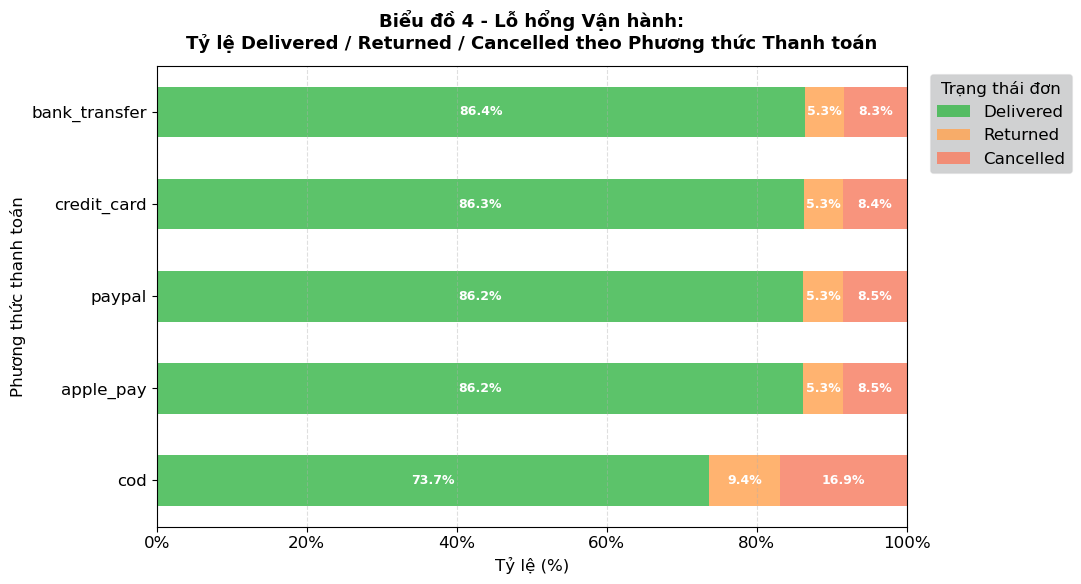

In [21]:
# ── Chart 3: 100% Stacked Bar – Payment Method × Order Status ──
STATUS_KEEP   = ['delivered','returned','cancelled']
STATUS_COLORS = {'delivered': '#3FB950', 'returned': '#FFA657', 'cancelled': '#F78166'}

df3 = orders[orders['order_status'].isin(STATUS_KEEP)].copy()
pivot3 = df3.groupby(['payment_method','order_status'])['order_id'].count().unstack(fill_value=0)
for s in STATUS_KEEP:
    if s not in pivot3.columns:
        pivot3[s] = 0
pivot3 = pivot3[STATUS_KEEP]
pivot3_pct = pivot3.div(pivot3.sum(axis=1), axis=0) * 100
pivot3_pct = pivot3_pct.sort_values('delivered', ascending=True)

fig, ax = plt.subplots(figsize=(11, 6))

bottom = np.zeros(len(pivot3_pct))
for status in STATUS_KEEP:
    vals = pivot3_pct[status].values
    ax.barh(pivot3_pct.index, vals, left=bottom,
            label=status.capitalize(), color=STATUS_COLORS[status], alpha=0.85, height=0.55)
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 3:
            ax.text(b + v/2, i, f'{v:.1f}%', ha='center', va='center',
                    fontsize=9, color='white', fontweight='bold')
    bottom += vals

ax.set_xlim(0, 100)
ax.set_xlabel('Tỷ lệ (%)', fontsize=12)
ax.set_ylabel('Phương thức thanh toán', fontsize=12)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x)}%'))
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.legend(title='Trạng thái đơn', loc='upper left', bbox_to_anchor=(1.02, 1), framealpha=0.2, facecolor='#161B22')
plt.title('Biểu đồ 4 - Lỗ hổng Vận hành:\nTỷ lệ Delivered / Returned / Cancelled theo Phương thức Thanh toán',
          fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
# plt.savefig(BASE_DIR + 'chart3_payment_status.png', dpi=150, bbox_inches='tight')
plt.show()



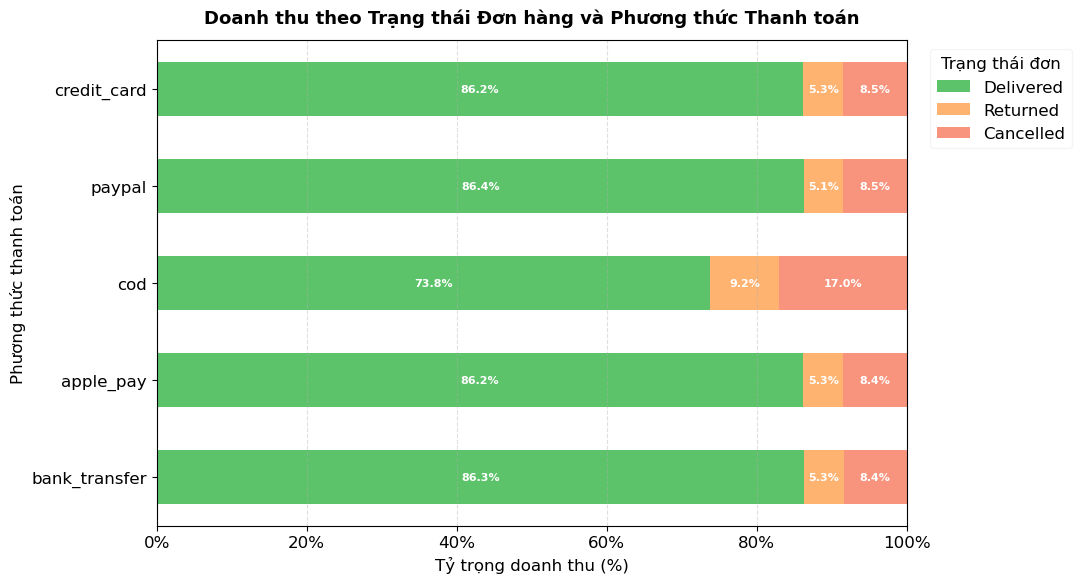

In [22]:
# ── Revenue theo Payment Method × Order Status ──

STATUS_KEEP   = ['delivered','returned','cancelled']
STATUS_COLORS = {
    'delivered': '#3FB950',
    'returned': '#FFA657',
    'cancelled': '#F78166'
}

# =========================
# Gộp orders với payments
# =========================
df_rev = orders.merge(
    payments[['order_id', 'payment_method', 'payment_value']],
    on='order_id',
    how='inner'
)

# Chỉ giữ các trạng thái cần phân tích
df_rev = df_rev[df_rev['order_status'].isin(STATUS_KEEP)].copy()

# =========================
# Tổng doanh thu theo:
# payment_method × order_status
# =========================
pivot_rev = (
    df_rev
    .groupby(['payment_method_x', 'order_status'])['payment_value']
    .sum()
    .unstack(fill_value=0)
)

# Đảm bảo đủ cột
for s in STATUS_KEEP:
    if s not in pivot_rev.columns:
        pivot_rev[s] = 0

pivot_rev = pivot_rev[STATUS_KEEP]

# =========================
# Tính tỷ trọng %
# =========================
pivot_rev_pct = pivot_rev.div(
    pivot_rev.sum(axis=1),
    axis=0
) * 100

# Sort theo doanh thu delivered
pivot_rev_pct = pivot_rev_pct.loc[
    pivot_rev['delivered'].sort_values().index
]

# =========================
# VẼ BIỂU ĐỒ
# =========================
fig, ax = plt.subplots(figsize=(11, 6))

bottom = np.zeros(len(pivot_rev_pct))

for status in STATUS_KEEP:
    vals = pivot_rev_pct[status].values

    ax.barh(
        pivot_rev_pct.index,
        vals,
        left=bottom,
        label=status.capitalize(),
        color=STATUS_COLORS[status],
        alpha=0.85,
        height=0.55
    )

    # Hiển thị % + số tiền
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 3:

            payment_method = pivot_rev_pct.index[i]
            revenue = pivot_rev.loc[payment_method, status]

            ax.text(
                b + v/2,
                i,
                f'{v:.1f}%',
                ha='center',
                va='center',
                fontsize=8,
                color='white',
                fontweight='bold'
            )

    bottom += vals

# =========================
# FORMAT
# =========================
ax.set_xlim(0, 100)

ax.set_xlabel('Tỷ trọng doanh thu (%)', fontsize=12)
ax.set_ylabel('Phương thức thanh toán', fontsize=12)

ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{int(x)}%')
)

ax.grid(axis='x', linestyle='--', alpha=0.4)

ax.legend(
    title='Trạng thái đơn',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    framealpha=0.2
)

plt.title(
    'Doanh thu theo Trạng thái Đơn hàng và Phương thức Thanh toán',
    fontsize=13,
    fontweight='bold',
    pad=12
)

plt.tight_layout()
plt.show()

In [23]:
# ── Bảng 3.1: Số liệu Tuyệt đối – Payment Method × Order Status ──
from IPython.display import display

# Dùng lại pivot3 từ Chart 3
pivot3_abs = pivot3.sort_values('delivered', ascending=False).copy()
pivot3_abs['Tổng cộng'] = pivot3_abs.sum(axis=1)

# Format hiển thị bảng
styled_table = pivot3_abs.style.format("{:,.0f}") \
    .background_gradient(subset=['delivered'], cmap='Greens') \
    .background_gradient(subset=['returned'], cmap='Oranges') \
    .background_gradient(subset=['cancelled'], cmap='Reds') \
    .set_caption("Bảng 4.1: Số lượng Delivered / Returned / Cancelled theo Phương thức Thanh toán") \
    .set_table_styles([{
        'selector': 'caption',
        'props': [('font-size', '14px'), ('font-weight', 'bold'), ('color', '#E6EDF3'), ('padding-bottom', '10px')]
    }, {
        'selector': 'th, td',
        'props': [('padding', '8px 15px')]
    }])

display(styled_table)


order_status,delivered,returned,cancelled,Tổng cộng
payment_method,,,,
credit_card,"291,073","17,807","28,452","337,332"
paypal,"79,189","4,841","7,817","91,847"
cod,"67,355","8,620","15,468","91,443"
apple_pay,"52,836","3,269","5,190","61,295"
bank_transfer,"26,263","1,605","2,535","30,403"


**Analysis 4**:

- Dữ liệu chỉ ra một sự phân hóa cực kỳ rõ nét về tỷ lệ thành công dựa trên phương thức thanh toán. Phương thức thanh toán khi nhận hàng (COD) chính là nguyên nhân gốc rễ gây ra lỗ hổng doanh thu. Tỷ lệ đơn hàng bị hoàn trả (returned) và hủy (cancelled) ở nhóm COD cao áp đảo so với phần còn lại.

- Ngược lại, các phương thức thanh toán trả trước hoặc không tiền mặt như credit_card, apple_pay có tỷ lệ giao hàng thành công (delivered) gần như tuyệt đối.

- Kết luận: Lỗ hổng không nằm ở chất lượng sản phẩm mà nằm ở hành vi thanh toán rủi ro. Việc cho phép sử dụng COD quá dễ dãi đang tạo ra tâm lý mua hàng thiếu cam kết, đẩy chi phí vận chuyển ngược (reverse logistics) lên cao.

In [25]:
payments.sort_values(by  = "payment_value")

,order_id,payment_method,payment_value,installments
583768,752798,apple_pay,389.7400,2
108263,139713,credit_card,428.2000,2
186582,240678,paypal,428.3400,2
353429,455819,credit_card,428.9400,1
349551,450847,cod,429.0700,1
...,...,...,...,...
436727,563097,cod,"246,463.2000",1
469234,605128,cod,"250,034.8800",1
488354,629691,credit_card,"269,154.2200",3
489769,631538,apple_pay,"271,911.6700",1


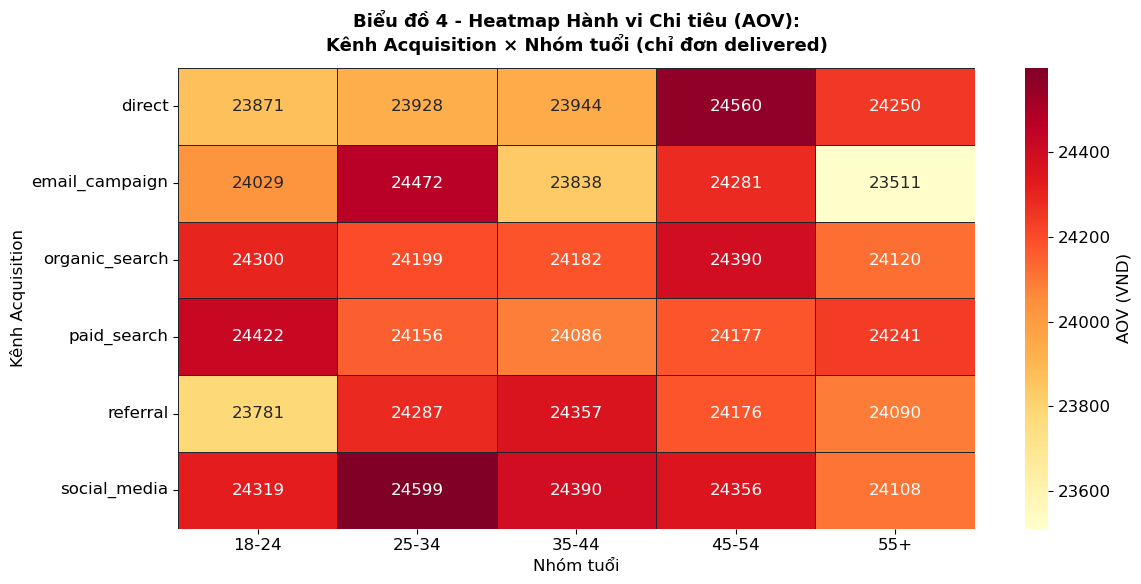

In [26]:
# ── Chart 4: Heatmap AOV – Age Group × Acquisition Channel ──
AGE_ORDER = ['18-24','25-34','35-44','45-54','55+']

df_del = orders[orders['order_status'] == 'delivered'].copy()
df_del = df_del.merge(payments[['order_id','payment_value']], on='order_id', how='left')
df_del = df_del.merge(customers[['customer_id','age_group','acquisition_channel']], on='customer_id', how='left')

pivot4 = df_del.groupby(['acquisition_channel','age_group'])['payment_value'].mean().unstack()
pivot4 = pivot4.reindex(columns=[c for c in AGE_ORDER if c in pivot4.columns])

fig, ax = plt.subplots(figsize=(12, 6))

cmap = sns.color_palette("YlOrRd", as_cmap=True)
sns.heatmap(pivot4, ax=ax, cmap=cmap, annot=True, fmt='.0f',
            linewidths=0.5, linecolor='#21262D',
            cbar_kws={'label': 'AOV (VND)'})

ax.set_xlabel('Nhóm tuổi', fontsize=12)
ax.set_ylabel('Kênh Acquisition', fontsize=12)
plt.title('Biểu đồ 4 - Heatmap Hành vi Chi tiêu (AOV):\nKênh Acquisition × Nhóm tuổi (chỉ đơn delivered)',
          fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
# plt.savefig(BASE_DIR + 'chart4_heatmap_aov.png', dpi=150, bbox_inches='tight')
plt.show()


**Nhận xét**:

Bản đồ nhiệt cho thấy sức mua không được chia đều mà tập trung cục bộ vào những "điểm ngọt" (sweet-spots) nhất định. Mỗi tệp khách hàng lại có một kênh chuyển đổi mang lại giá trị cao riêng biệt:

- Khách hàng trẻ (18-24 tuổi) sẵn sàng chi trả mức AOV cao nhất khi tiếp cận qua kênh email_campaign.

- Khách hàng trung niên (35-44 tuổi) mang lại giá trị tốt nhất khi họ chủ động tìm kiếm (organic_search).

- Đặc biệt, nhóm khách hàng lớn tuổi (45-54 và 55+) cho thấy mức chi tiêu rất lớn qua kênh truyền miệng/giới thiệu (referral).

> Kết luận: Khách hàng đến từ các kênh khác nhau có mức độ nhạy cảm về giá và khả năng chi trả khác nhau. Việc đổ đồng một ngân sách hoặc một thông điệp Marketing cho tất cả các kênh là không hiệu quả.

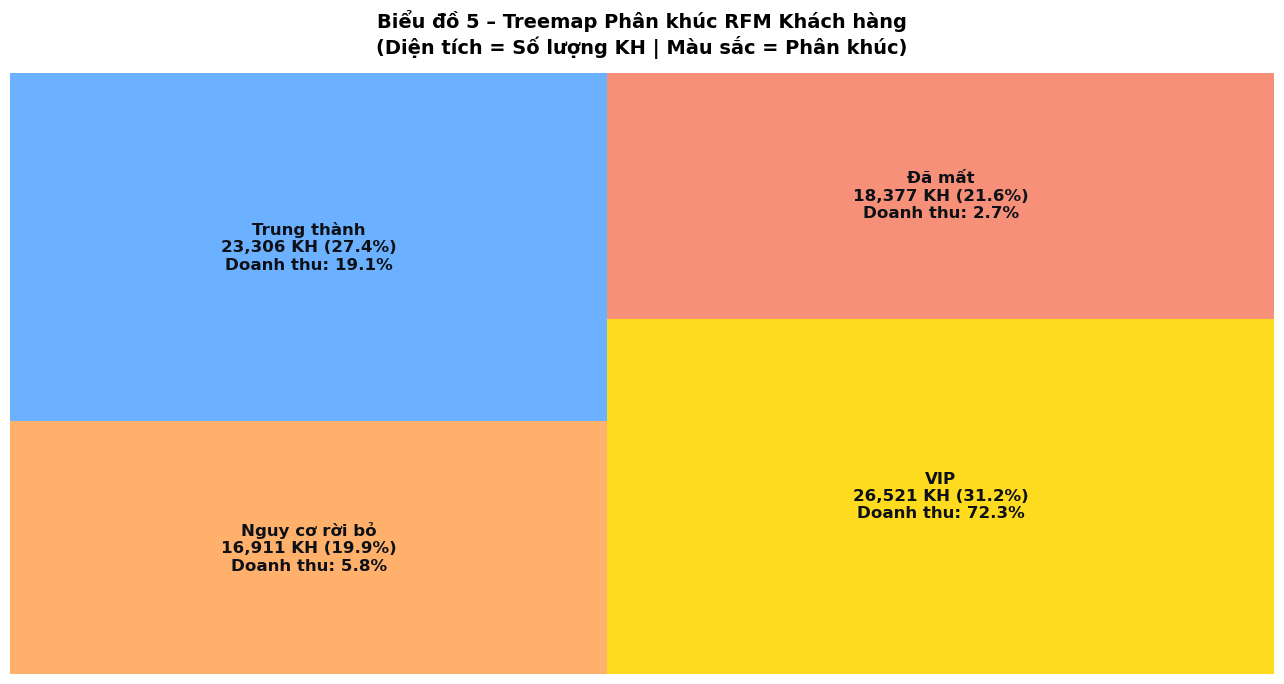

In [28]:
# ── Chart 5: RFM Treemap ──
orders["order_date"] = pd.to_datetime(orders["order_date"])
df_rfm = orders[orders['order_status'] == 'delivered'].copy()
df_rfm = df_rfm.merge(payments[['order_id','payment_value']], on='order_id', how='left')

ref_date = df_rfm['order_date'].max() + pd.Timedelta(days=1)
rfm = df_rfm.groupby('customer_id').agg(
    recency   = ('order_date',    lambda x: (ref_date - x.max()).days),
    frequency = ('order_id',      'count'),
    monetary  = ('payment_value', 'sum')
).reset_index()

# Score 1-4 (recency: lower=better => invert)
rfm['R'] = pd.qcut(rfm['recency'],   4, labels=[4,3,2,1]).astype(int)
rfm['F'] = pd.qcut(rfm['frequency'].rank(method='first'), 4, labels=[1,2,3,4]).astype(int)
rfm['M'] = pd.qcut(rfm['monetary'].rank(method='first'),  4, labels=[1,2,3,4]).astype(int)
rfm['RFM_Score'] = rfm['R'] + rfm['F'] + rfm['M']

def segment(score):
    if score >= 10: return 'VIP'
    if score >= 7:  return 'Trung thành'
    if score >= 5:  return 'Nguy cơ rời bỏ'
    return 'Đã mất'

rfm['Segment'] = rfm['RFM_Score'].apply(segment)

seg_stats = rfm.groupby('Segment').agg(
    customers = ('customer_id', 'count'),
    revenue   = ('monetary',    'sum')
).reset_index()

total_rev  = seg_stats['revenue'].sum()
total_cust = seg_stats['customers'].sum()
seg_stats['rev_pct']  = seg_stats['revenue']  / total_rev  * 100
seg_stats['cust_pct'] = seg_stats['customers'] / total_cust * 100

SEG_COLORS = {
    'VIP':            '#FFD700',
    'Trung thành':    '#58A6FF',
    'Nguy cơ rời bỏ': '#FFA657',
    'Đã mất':         '#F78166',
}

fig, ax = plt.subplots(figsize=(13, 7))
colors = [SEG_COLORS.get(s, '#888') for s in seg_stats['Segment']]
labels = [
    f"{row['Segment']}\n{row['customers']:,} KH ({row['cust_pct']:.1f}%)\nDoanh thu: {row['rev_pct']:.1f}%"
    for _, row in seg_stats.iterrows()
]

squarify.plot(
    sizes=seg_stats['customers'].values,
    label=labels,
    color=colors,
    alpha=0.88,
    text_kwargs={'fontsize': 12, 'fontweight': 'bold', 'color': '#0D1117'},
    ax=ax
)
ax.axis('off')
plt.title('Biểu đồ 5 – Treemap Phân khúc RFM Khách hàng\n(Diện tích = Số lượng KH | Màu sắc = Phân khúc)',
          fontsize=14, fontweight='bold', pad=14)

# Summary annotation
summary_txt = "\n".join([
    f"  {row['Segment']}: {row['cust_pct']:.1f}% KH → {row['rev_pct']:.1f}% Doanh thu"
    for _, row in seg_stats.iterrows()
])
plt.tight_layout()
# plt.savefig(BASE_DIR + 'chart5_rfm_treemap.png', dpi=150, bbox_inches='tight')
plt.show()
# print("✅ Chart 5 saved")


In [29]:
print(summary_txt)

  Nguy cơ rời bỏ: 19.9% KH → 5.8% Doanh thu
  Trung thành: 27.4% KH → 19.1% Doanh thu
  VIP: 31.2% KH → 72.3% Doanh thu
  Đã mất: 21.6% KH → 2.7% Doanh thu


- Chỉ với **31.2%** lượng khách hàng thuộc nhóm **VIP**, nhóm này đã tạo ra sức mạnh gánh vác tới **72.3%** tổng doanh thu của toàn hệ thống. Điều này cho thấy sự tập trung doanh thu cực kỳ lớn vào một tệp khách hàng lõi.
- **Tiềm năng từ nhóm Trung thành:** Nhóm **Trung thành** chiếm **27.4%** số lượng nhưng chỉ mới đóng góp **19.1%** doanh thu. Đây là một tệp "nguồn" rất tiềm năng để Upsell/Cross-sell nhằm chuyển đổi họ lên thành nhóm VIP.
- **Tình trạng "chảy máu" khách hàng:** Có một sự thật đáng báo động là nhóm **Đã mất** và **Nguy cơ rời bỏ** cộng lại chiếm tới **hơn 41.4%** tổng số khách hàng, nhưng chỉ mang lại vỏn vẹn **~8.5%** doanh thu. 
- **Kết luận:** Doanh nghiệp đang tồn tại sự phân hóa rất mạnh về giá trị vòng đời khách hàng. Chiến lược cấp thiết nhất không phải là tiếp tục "đốt tiền" chạy quảng cáo tìm khách mới (bù đắp cho 41% khách hàng đã rời bỏ/ngủ đông), mà là phải dồn nguồn lực chăm sóc và khai thác tối đa nhóm VIP, đồng thời xây dựng kịch bản Retargeting tự động để "đánh thức" nhóm Nguy cơ rời bỏ trước khi họ hoàn toàn trở thành nhóm Đã mất.

### **Phần B: TỔNG HỢP INSIGHT**

**1. Descriptive (Thực trạng - Điều gì đang xảy ra?)**
- Doanh thu và quy mô đơn hàng duy trì đà tăng trưởng tốt. Tuy nhiên, **lợi nhuận thực tế lại biến động mạnh và biên lợi nhuận khá mỏng**.
- Tập khách hàng cốt lõi và đông đảo nhất hiện tại là giới trẻ (GenZ & Millennials từ 18-34 tuổi).

**2. Diagnostic (Chẩn đoán - Tại sao lại xảy ra?)**
- Điểm rò rỉ lợi nhuận lớn nhất nằm ở **Lỗ hổng Vận hành**: Tỷ lệ huỷ (Cancelled) và hoàn đơn (Returned) đặc biệt cao ở nhóm thanh toán **COD**.
- Khách hàng trẻ có xu hướng mua sắm bốc đồng nhưng lại ưu tiên sử dụng COD. Điều này dẫn đến chi phí logistics (cước hoàn hàng) và các chi phí ẩn "ăn mòn" phần lớn lợi nhuận gộp của doanh nghiệp.

**3. Predictive (Dự báo - Hệ quả nếu tiếp diễn?)**
- Nếu tiếp tục mô hình "đốt tiền" chạy quảng cáo để thu hút tệp mass (GenZ) mà không kiểm soát rủi ro từ phương thức thanh toán, doanh nghiệp sẽ rơi vào vòng lặp **"Tăng trưởng ảo"**: Doanh thu (top-line) tăng trưởng liên tục nhưng dòng tiền và lợi nhuận thực tế (bottom-line) ngày càng teo tóp.

**4. Prescriptive (Khuyến nghị - Cần hành động gì?)**
- **Vận hành:** Cần áp dụng rào cản mềm đối với phương thức COD (VD: áp dụng phí vận chuyển cao hơn cho COD, hoặc yêu cầu đặt cọc một phần). Song song đó, khuyến khích thanh toán trước (VNPay/Credit Card) bằng Voucher hoặc Freeship.
- **Tiếp thị & Chăm sóc khách hàng:** Chuyển dịch một phần trọng tâm ngân sách sang tập khách hàng **VIP & Trung thành** (đã được định vị rõ qua phân khúc RFM). Nhóm này có AOV (giá trị đơn hàng) cao và tỷ lệ hoàn trả rất thấp. Cần xây dựng các chương trình Loyalty đặc quyền để tối đa hóa LTV (Customer Lifetime Value).

# **PHẦN 2: Hiệu suất vận hành**
### Mục tiêu

Dashboard này trả lời 5 câu hỏi vận hành cốt lõi bằng một bức tranh tổng hợp:

1. **Đơn hàng biến động thế nào qua thời gian?** *(Orders over time)*
2. **Danh mục nào tạo ra doanh thu & lợi nhuận cao nhất?** *(Revenue & Profit by category)*
3. **Tồn kho đang phân bổ có hợp lý với nhu cầu thực tế không?** *(Inventory vs demand)*
4. **Danh mục nào có tỷ lệ hoàn hàng cao nhất – rủi ro vận hành ở đâu?** *(Return rate)*
5. **Thời gian giao hàng trung bình có đang đáp ứng kỳ vọng khách hàng?** *(Delivery time)*

In [33]:
order_items = pd.read_csv(path_dataClean + 'cleaned_order_items.csv', low_memory=False)
web_traffic = pd.read_csv(path_dataClean + 'web_traffic_cleaned.csv', parse_dates=['date'], low_memory=False)
promotions  = pd.read_csv(path_dataClean + 'promotions_cleaned.csv', parse_dates=['start_date', 'end_date'], low_memory=False)
reviews     = pd.read_csv(path_dataClean + 'cleaned_reviews.csv',    parse_dates=['review_date'], low_memory=False)
returns     = pd.read_csv(path_dataClean + 'cleaned_returns.csv',    parse_dates=['return_date'], low_memory=False)
products    = pd.read_csv(path_dataClean + 'product_cleaned.csv',   low_memory=False)
shipments   = pd.read_csv(path_dataClean + 'cleaned_shipments.csv',  parse_dates=['ship_date', 'delivery_date'], low_memory=False)
inventory   = pd.read_csv(path_dataClean + 'inventory_cleaned.csv', low_memory=False)

In [34]:
# Chuẩn bị dữ liệu cho Phần 2 (Sử dụng lại DataFrames từ Phần 1 để đồng bộ)
p2_order_items = order_items.copy()
p2_orders = orders.copy()
p2_products = pd.read_csv(path_dataClean + 'product_cleaned.csv', low_memory=False)
p2_shipments = shipments.copy()
p2_inventory = inventory.copy()
p2_returns = returns.copy()

# Tính toán thời gian giao hàng
p2_shipments['delivery_time'] = (p2_shipments['delivery_date'] - p2_shipments['ship_date']).dt.days

# Ghép nối dữ liệu để tính toán
p2_order_items = p2_order_items.merge(
    p2_orders[['order_id', 'order_date']],
    on='order_id',
    how='left'
)

p2_order_items = p2_order_items.merge(
    p2_products[['product_id', 'category', 'cogs']],
    on='product_id',
    how='left'
)

p2_order_items = p2_order_items.dropna(subset=['order_date'])

# Tính Doanh thu và Lợi nhuận
p2_order_items['revenue'] = p2_order_items['quantity'] * p2_order_items['unit_price']
p2_order_items['profit'] = (
    p2_order_items['revenue']
    - p2_order_items['discount_amount']
    - (p2_order_items['quantity'] * p2_order_items['cogs'])
)


In [35]:
orders_time = p2_order_items.groupby(p2_order_items['order_date'].dt.date).size()

rev_cat = p2_order_items.groupby("category")['revenue'].sum().sort_values()
profit_cat = p2_order_items.groupby("category")['profit'].sum().sort_values()
p2_inventory_cat = p2_inventory.groupby("category")['stock_on_hand'].sum().sort_values()

orders_cat_count = p2_order_items.groupby("category").size()

p2_returns_cat = p2_returns.merge(
    p2_order_items[['order_id', 'product_id', 'category']],
    on=['order_id', 'product_id'],
    how='left'
)

p2_returns_cat_count = p2_returns_cat.groupby("category").size()
return_rate = (p2_returns_cat_count / orders_cat_count).fillna(0).sort_values()

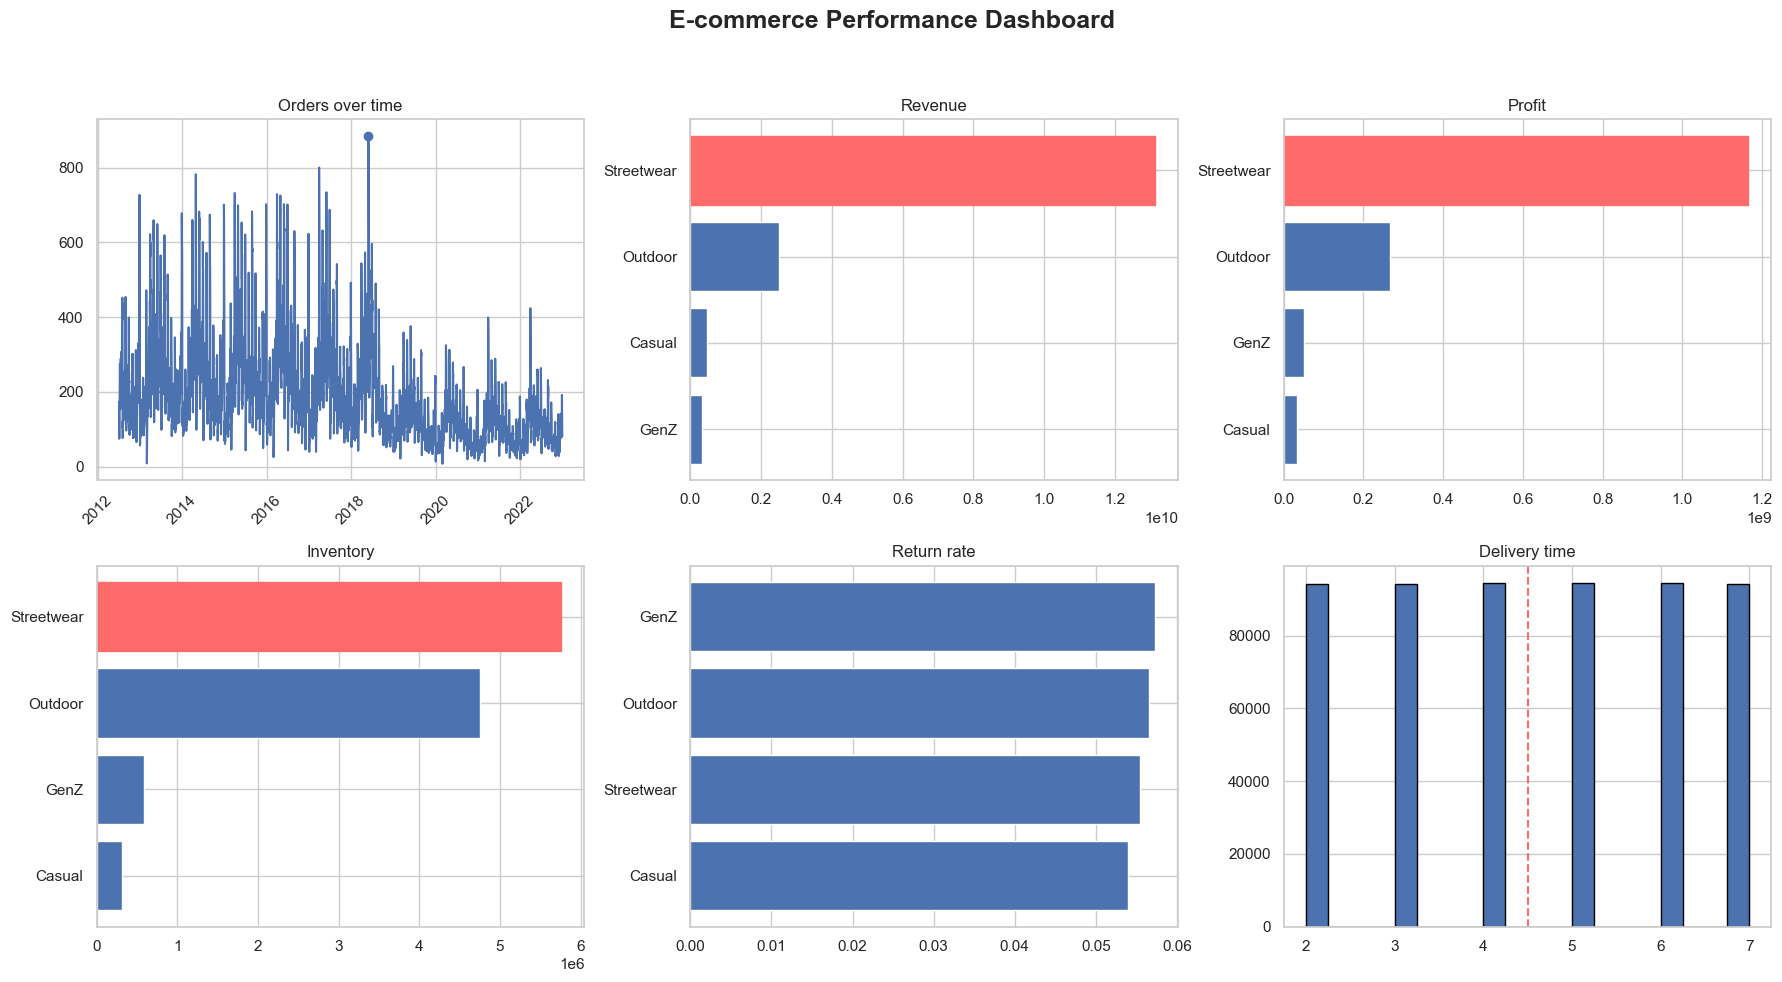

In [36]:
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook") # Thiết lập lại theme cho Phần 2
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("E-commerce Performance Dashboard", fontsize=18, fontweight='bold')

# Orders
axs[0, 0].plot(orders_time.index, orders_time.values)
peak_day = orders_time.idxmax()
peak_val = orders_time.max()
axs[0, 0].scatter(peak_day, peak_val)
axs[0, 0].set_title("Orders over time")
axs[0, 0].tick_params(axis='x', rotation=45)

# Revenue
bars = axs[0, 1].barh(rev_cat.index, rev_cat.values)
bars[-1].set_color(highlight_color)
axs[0, 1].set_title("Revenue")

# Profit
bars = axs[0, 2].barh(profit_cat.index, profit_cat.values)
bars[-1].set_color(highlight_color)
axs[0, 2].set_title("Profit")

# Inventory
bars = axs[1, 0].barh(p2_inventory_cat.index, p2_inventory_cat.values)
bars[-1].set_color(highlight_color)
axs[1, 0].set_title("Inventory")

# Return rate
colors_grad = plt.cm.Pastel1(np.linspace(0.3, 0.9, len(return_rate)))
axs[1, 1].barh(return_rate.index, return_rate.values)
axs[1, 1].set_title("Return rate")

# Delivery
axs[1, 2].hist(p2_shipments['delivery_time'], bins=20, edgecolor='black')
mean_val = p2_shipments['delivery_time'].mean()
axs[1, 2].axvline(mean_val, color=highlight_color, linestyle='--')
axs[1, 2].set_title("Delivery time")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


##### **Chart 1 — Orders over time**

- Lượng đơn hàng **không đều** qua thời gian, có những đỉnh spike rõ rệt — gợi ý hoạt động kinh doanh chịu tác động mạnh bởi **campaign theo mùa vụ hoặc sự kiện khuyến mãi** (flash sale, double-day).
- Ngoài các đỉnh đó, baseline đơn hàng hàng ngày ở mức khá ổn định — nền tảng có **lượng khách hàng thường xuyên** nhất định.
- **Implication:** Cần chuẩn bị năng lực vận hành (kho, vận chuyển, nhân sự) theo chu kỳ spike, không theo mức trung bình.

##### **Chart 2 & 3 — Revenue & Profit by Category**

- Danh mục dẫn đầu về **doanh thu** không nhất thiết là danh mục dẫn đầu về **lợi nhuận** — biên lợi nhuận khác nhau đáng kể giữa các category.
- Nếu một category có revenue cao nhưng profit thấp, khả năng chi phí discount, COGS hoặc tỷ lệ hoàn hàng đang ăn mòn biên.
- **Implication:** Chiến lược pricing và khuyến mãi nên được thiết kế riêng theo category, tránh áp dụng đồng loạt discount vào các mặt hàng margin mỏng.


##### **Chart 4 — Inventory by Category**

- Nếu một category có **tồn kho lớn nhưng revenue thấp** — dấu hiệu overstock (dead stock, vốn bị chôn, tốn chi phí lưu kho).
- Ngược lại, category có demand cao nhưng inventory thấp — nguy cơ stockout, mất doanh thu cơ hội.
- **Implication:** Cần rebalance kế hoạch nhập hàng theo tỷ lệ sell-through thực tế.

##### **Chart 5 — Return Rate by Category**

- Danh mục có tỷ lệ hoàn hàng cao nhất là điểm nóng rủi ro vận hành — mỗi đơn hoàn không chỉ mất doanh thu mà còn phát sinh chi phí logistics ngược.
- Return rate cao thường liên quan đến: mô tả sản phẩm không khớp thực tế, chất lượng không đồng đều, hoặc thói quen mua thử-trả của một phân khúc khách hàng.
- **Implication:** Ưu tiên cải thiện product page và kiểm soát chất lượng tại category có return rate > 20%.

##### **Chart 6 — Delivery Time Distribution**

- Nếu phân phối có đuôi dài bên phải (long tail) — một bộ phận đơn hàng bị giao trễ đáng kể, ảnh hưởng trực tiếp đến satisfaction score và nguy cơ hoàn hàng.
- **Implication:** Xác định ngưỡng SLA giao hàng và theo dõi % đơn vi phạm SLA theo từng khu vực/carrier.


### **Tổng kết insight**
**Descriptive — Thực trạng:**  
Lượng đơn hàng tăng trưởng theo thời gian với baseline ổn định, nhưng phân bổ doanh thu và lợi nhuận tập trung không đều giữa các danh mục sản phẩm. Tồn kho hiện tại chưa phản ánh đúng cơ cấu nhu cầu thực tế.

**Diagnostic — Nguyên nhân:**  
Sự chênh lệch giữa revenue và profit theo category cho thấy chi phí COGS, discount và tỷ lệ hoàn hàng phân hóa mạnh. Một số danh mục tạo volume lớn nhưng biên thực nhận thấp do chiết khấu cao hoặc chất lượng không đồng đều dẫn đến hoàn hàng.

**Predictive — Xu hướng:**  
Các spike đơn hàng theo sự kiện có tính lặp lại, cho phép dự báo nhu cầu theo mùa vụ. Category có return rate cao và tồn kho tồn đọng có nguy cơ kéo dài tình trạng kém hiệu quả nếu không được can thiệp.

**Prescriptive — Khuyến nghị:**  
Tái cân bằng kế hoạch nhập hàng và kiểm soát discount riêng theo từng danh mục. Ưu tiên cải thiện chất lượng sản phẩm và mô tả listing cho các category có return rate > 20%. Thiết lập SLA giao hàng và theo dõi tỷ lệ vi phạm theo khu vực để giảm thiểu đơn trễ.

# **PHẦN 3: Marketing - Tăng trưởng**

#### 1. Data preparation: tạo bảng phân tích marketing
Kênh marketing nào đang tạo tăng trưởng thật sự: kéo traffic, chuyển đổi thành đơn hàng, tạo doanh thu/lợi nhuận, giữ trải nghiệm khách hàng tốt, và nên được ưu tiên đầu tư?

Ta cần nối các bảng:
- `orders`: đơn hàng, ngày, `order_source`
- `order_items`: sản phẩm trong đơn, giá sau giảm, khuyến mãi
- `products`: category/segment/COGS để tính biên lợi nhuận ước tính
- `payments`: payment value
- `web_traffic`: sessions, visitors, page views, bounce rate
- `reviews`, `returns`: chất lượng khách hàng và hậu mãi

In [41]:
orders = orders.copy()
order_items = order_items.copy()
web = web_traffic.copy()
promotions = promotions.copy()
reviews = reviews.copy()
returns = returns.copy()
products = pd.read_csv(path_dataClean + 'product_cleaned.csv', low_memory=False)
payments = payments.copy()
shipments = shipments.copy()
customers = customers.copy()
geo = geo.copy()

# Chuẩn hóa tháng
orders["year_month"] = orders["order_date"].dt.to_period("M").dt.to_timestamp()
orders["year"] = orders["order_date"].dt.year
orders["month"] = orders["order_date"].dt.month
web["year_month"] = web["date"].dt.to_period("M").dt.to_timestamp()
web["year"] = web["date"].dt.year
web["month"] = web["date"].dt.month

# Join order_items với product để tính revenue/margin ước tính
items = order_items.merge(
    products[["product_id", "product_name", "category", "segment", "size", "price", "cogs"]],
    on="product_id",
    how="left"
)

items["line_revenue"] = items["quantity"] * items["unit_price"]
items["gross_profit_est"] = items["quantity"] * (items["unit_price"] - items["cogs"])
items["has_promo"] = items["promo_id"].notna() | items["promo_id_2"].notna()

# Tổng hợp lên cấp order
order_value = items.groupby("order_id", as_index=False).agg(
    item_lines=("product_id", "count"),
    total_qty=("quantity", "sum"),
    order_revenue=("line_revenue", "sum"),
    order_discount=("discount_amount", "sum"),
    gross_profit_est=("gross_profit_est", "sum"),
    promo_lines=("has_promo", "sum")
)
order_value["has_any_promo"] = order_value["promo_lines"] > 0

orders_enriched = (
    orders
    .merge(order_value, on="order_id", how="left")
    .merge(payments[["order_id", "payment_value", "installments"]], on="order_id", how="left")
)

orders_enriched.head()

,order_id,order_date,customer_id,zip,order_status,payment_method,device_type,order_source,year_month,year,month,item_lines,total_qty,order_revenue,order_discount,gross_profit_est,promo_lines,has_any_promo,payment_value,installments
0,1,2012-07-04,58578,1109,delivered,credit_card,desktop,paid_search,2012-07-01,2012,7,1,7,"7,967.5400",0.0000,590.9539,0,False,"7,967.5400",3
1,2,2012-07-04,58621,1330,returned,cod,mobile,paid_search,2012-07-01,2012,7,1,7,"71,163.7500",0.0000,"8,249.8204",0,False,"71,163.7500",1
2,3,2012-07-04,58811,1473,delivered,credit_card,desktop,direct,2012-07-01,2012,7,1,3,"33,660.9900",0.0000,"3,387.9532",0,False,"33,660.9900",3
3,4,2012-07-04,59453,2360,delivered,credit_card,desktop,referral,2012-07-01,2012,7,1,5,"53,196.2500",0.0000,"7,169.0976",0,False,"53,196.2500",3
4,6,2012-07-06,57821,2886,delivered,paypal,mobile,email_campaign,2012-07-01,2012,7,1,1,"1,597.8400",0.0000,549.1436,0,False,"1,597.8400",1


In [42]:
# Quick data health check
print("Order date range:", orders_enriched["order_date"].min(), "to", orders_enriched["order_date"].max())
print("Web date range:", web["date"].min(), "to", web["date"].max())
print("\nMissing values in key columns:")
display(orders_enriched[["order_source", "order_revenue", "gross_profit_est", "has_any_promo"]].isna().mean().to_frame("missing_rate"))
display(web.isna().mean().to_frame("missing_rate"))

Order date range: 2012-07-04 00:00:00 to 2022-12-31 00:00:00
Web date range: 2013-01-01 00:00:00 to 2022-12-31 00:00:00

Missing values in key columns:


,missing_rate
order_source,0.0000
order_revenue,0.0000
gross_profit_est,0.0000
has_any_promo,0.0000


,missing_rate
date,0.0000
sessions,0.0000
unique_visitors,0.0000
page_views,0.0000
bounce_rate,0.0000
avg_session_duration_sec,0.0000
traffic_source,0.0000
month,0.0000
day_of_week,0.0000
day_name,0.0000


In [43]:
# 1. TẠO monthly_orders
monthly_orders = orders_enriched.groupby(
    ["year_month", "order_source"], as_index=False
).agg(
    orders=("order_id", "count"),
    revenue=("order_revenue", "sum"),
    gross_profit=("gross_profit_est", "sum")
)

# 2. TẠO monthly_web
monthly_web = web.groupby(
    ["year_month", "traffic_source"], as_index=False
).agg(
    sessions=("sessions", "sum"),
    unique_visitors=("unique_visitors", "sum"),
    page_views=("page_views", "sum"),
    bounce_rate=("bounce_rate", "mean"),
    avg_session_duration_sec=("avg_session_duration_sec", "mean")
)

# 3. MERGE → TẠO funnel
funnel = monthly_web.merge(
    monthly_orders,
    left_on=["year_month", "traffic_source"],
    right_on=["year_month", "order_source"],
    how="left"
)

# Fill NaN
funnel["orders"] = funnel["orders"].fillna(0)
funnel["revenue"] = funnel["revenue"].fillna(0)
funnel["gross_profit"] = funnel["gross_profit"].fillna(0)

# Metrics
funnel["conversion_proxy"] = funnel["orders"] / funnel["sessions"]
funnel["revenue_per_session"] = funnel["revenue"] / funnel["sessions"]
funnel["profit_per_session"] = funnel["gross_profit"] / funnel["sessions"]

,order_source,orders,revenue,gross_profit,aov,avg_margin_per_order,order_share,revenue_share,profit_share
2,organic_search,"181,495","4,595,516,711","635,104,309","25,320","3,499",28.1%,28.0%,28.0%
3,paid_search,"141,652","3,606,943,187","496,923,803","25,463","3,508",21.9%,22.0%,21.9%
5,social_media,"129,710","3,289,598,708","453,262,171","25,361","3,494",20.0%,20.0%,20.0%
1,email_campaign,"77,572","1,972,621,080","274,454,703","25,430","3,538",12.0%,12.0%,12.1%
4,referral,"64,565","1,640,764,180","223,848,074","25,413","3,467",10.0%,10.0%,9.9%
0,direct,"51,951","1,325,032,720","183,433,006","25,505","3,531",8.0%,8.1%,8.1%


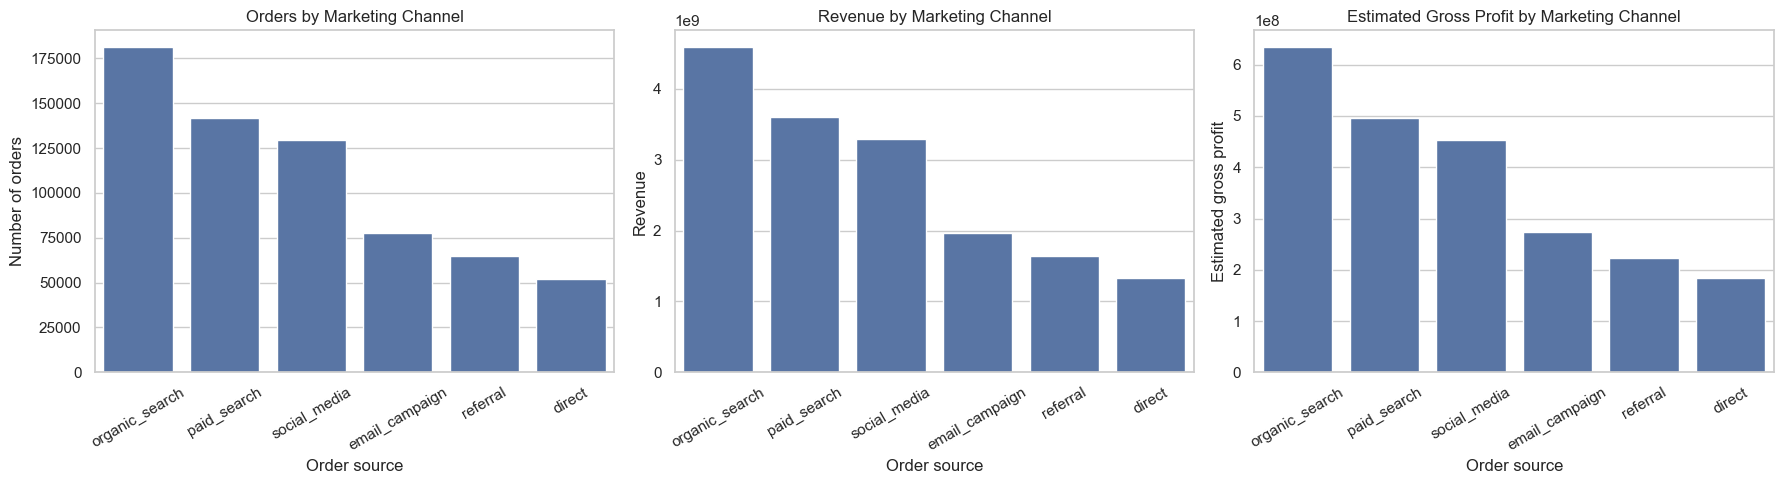

In [44]:
channel_summary = orders_enriched.groupby("order_source", as_index=False).agg(
    orders=("order_id", "count"),
    revenue=("order_revenue", "sum"),
    gross_profit=("gross_profit_est", "sum"),
    aov=("order_revenue", "mean"),
    avg_margin_per_order=("gross_profit_est", "mean")
)

channel_summary["order_share"] = channel_summary["orders"] / channel_summary["orders"].sum()
channel_summary["revenue_share"] = channel_summary["revenue"] / channel_summary["revenue"].sum()
channel_summary["profit_share"] = channel_summary["gross_profit"] / channel_summary["gross_profit"].sum()
channel_summary = channel_summary.sort_values("revenue", ascending=False)

display(channel_summary.style.format({
    "orders": "{:,.0f}",
    "revenue": "{:,.0f}",
    "gross_profit": "{:,.0f}",
    "aov": "{:,.0f}",
    "avg_margin_per_order": "{:,.0f}",
    "order_share": "{:.1%}",
    "revenue_share": "{:.1%}",
    "profit_share": "{:.1%}",
}))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=channel_summary, x="order_source", y="orders", ax=axes[0])
axes[0].set_title("Orders by Marketing Channel")
axes[0].set_xlabel("Order source")
axes[0].set_ylabel("Number of orders")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=channel_summary, x="order_source", y="revenue", ax=axes[1])
axes[1].set_title("Revenue by Marketing Channel")
axes[1].set_xlabel("Order source")
axes[1].set_ylabel("Revenue")
axes[1].tick_params(axis="x", rotation=30)

sns.barplot(data=channel_summary, x="order_source", y="gross_profit", ax=axes[2])
axes[2].set_title("Estimated Gross Profit by Marketing Channel")
axes[2].set_xlabel("Order source")
axes[2].set_ylabel("Estimated gross profit")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

#### **Analysis 1 — Descriptive insight**

- `organic_search` là kênh lớn nhất về **đơn hàng**, **doanh thu** và **gross profit ước tính**.
- Ba kênh lớn nhất thường là `organic_search`, `paid_search`, `social_media`, chiếm phần lớn tăng trưởng.
- Tuy nhiên, `AOV` giữa các kênh không chênh quá mạnh, nghĩa là khác biệt doanh thu chủ yếu đến từ **volume**, không phải do mỗi đơn hàng của kênh này đắt hơn hẳn kênh khác.

**Business implication:**  
Marketing không nên chỉ nhìn vào doanh thu tổng. Cần tách rõ:
- Kênh tạo volume lớn: phù hợp để scale.
- Kênh có hiệu quả chuyển đổi/lợi nhuận tốt: phù hợp để tối ưu ROI.

#### **Visualization 2 — Traffic funnel: Sessions → Orders → Revenue**

**Mục tiêu:** cấp **Diagnostic**: kênh nào kéo nhiều traffic nhưng chuyển đổi chưa tương xứng?

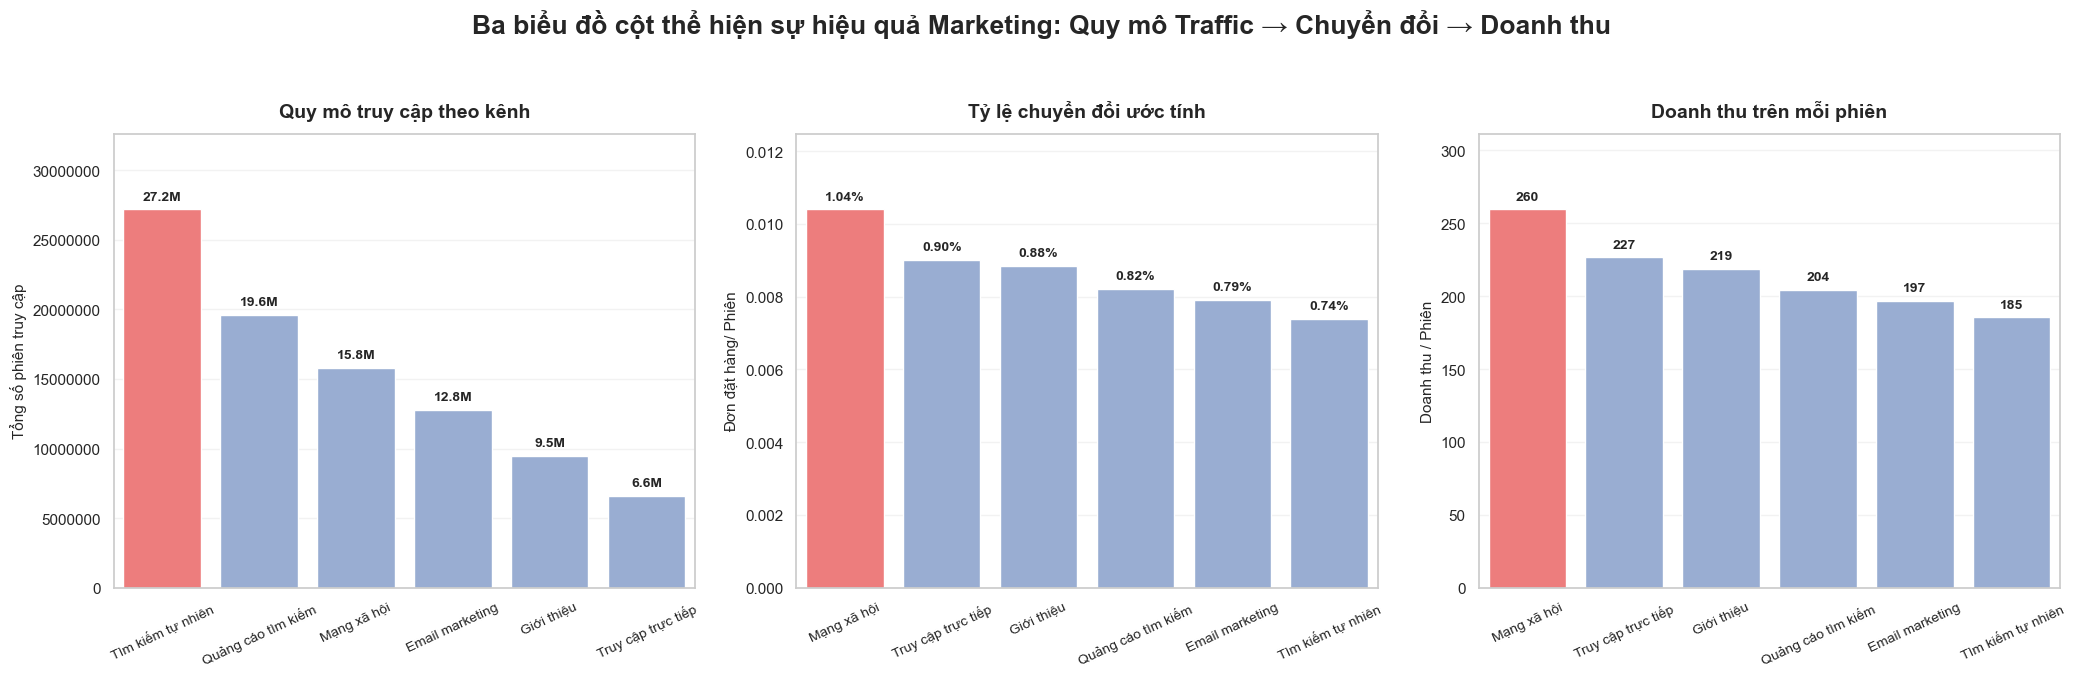

,traffic_source,traffic_source_vi,sessions,orders,revenue,gross_profit,conversion_proxy,revenue_per_session,profit_per_session
5,social_media,Mạng xã hội,"15,816,226","123,261","3,141,422,009","422,495,469",1.040%,259.58,33.85
0,direct,Truy cập trực tiếp,"6,571,549","42,891","1,100,009,291","149,765,843",0.902%,226.61,30.76
4,referral,Giới thiệu,"9,476,845","59,052","1,513,127,797","203,118,023",0.884%,218.78,29.55
3,paid_search,Quảng cáo tìm kiếm,"19,598,271","134,668","3,441,723,469","462,631,315",0.821%,204.39,27.23
1,email_campaign,Email marketing,"12,792,670","71,524","1,834,472,984","249,743,296",0.791%,196.67,27.22
2,organic_search,Tìm kiếm tự nhiên,"27,196,976","172,474","4,387,682,612","591,367,204",0.739%,185.38,25.63


In [47]:
# FUNNEL SUMMARY: WEB TRAFFIC + ORDERS

funnel_summary = funnel.groupby("traffic_source", as_index=False).agg(
    sessions=("sessions", "sum"),
    orders=("orders", "sum"),
    revenue=("revenue", "sum"),
    gross_profit=("gross_profit", "sum"),
    conversion_proxy=("conversion_proxy", "mean"),
    revenue_per_session=("revenue_per_session", "mean"),
    profit_per_session=("profit_per_session", "mean"),
)

source_labels = {
    "organic_search": "Tìm kiếm tự nhiên",
    "paid_search": "Quảng cáo tìm kiếm",
    "social_media": "Mạng xã hội",
    "email_campaign": "Email marketing",
    "referral": "Giới thiệu",
    "direct": "Truy cập trực tiếp"
}

# Sửa lỗi ở đây: dùng traffic_source, không dùng order_source
funnel_summary["traffic_source_vi"] = funnel_summary["traffic_source"].map(source_labels)

# Nếu có kênh nào không map được thì giữ tên gốc
funnel_summary["traffic_source_vi"] = funnel_summary["traffic_source_vi"].fillna(
    funnel_summary["traffic_source"]
)

# VISUALIZATION: MARKETING FUNNEL

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))

fig.suptitle(
    "Ba biểu đồ cột thể hiện sự hiệu quả Marketing: Quy mô Traffic → Chuyển đổi → Doanh thu",
    fontsize=19,
    fontweight="bold",
    y=1.04
)

plots = [
    {
        "ax": axes[0],
        "data": funnel_summary.sort_values("sessions", ascending=False),
        "x": "traffic_source_vi",
        "y": "sessions",
        "title": "Quy mô truy cập theo kênh",
        "ylabel": "Tổng số phiên truy cập",
        "fmt": lambda v: f"{v/1_000_000:.1f}M"
    },
    {
        "ax": axes[1],
        "data": funnel_summary.sort_values("conversion_proxy", ascending=False),
        "x": "traffic_source_vi",
        "y": "conversion_proxy",
        "title": "Tỷ lệ chuyển đổi ước tính",
        "ylabel": "Đơn đặt hàng/ Phiên",
        "fmt": lambda v: f"{v:.2%}"
    },
    {
        "ax": axes[2],
        "data": funnel_summary.sort_values("revenue_per_session", ascending=False),
        "x": "traffic_source_vi",
        "y": "revenue_per_session",
        "title": "Doanh thu trên mỗi phiên",
        "ylabel": "Doanh thu / Phiên",
        "fmt": lambda v: f"{v:,.0f}"
    }
]

for p in plots:
    ax = p["ax"]
    data = p["data"].copy()

    colors = ["#FF6B6B" if i == 0 else "#8FAADC" for i in range(len(data))]

    sns.barplot(
        data=data,
        x=p["x"],
        y=p["y"],
        ax=ax,
        palette=colors
    )

    ax.set_title(p["title"], fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("")
    ax.set_ylabel(p["ylabel"], fontsize=11)
    ax.tick_params(axis="x", rotation=25, labelsize=10)
    ax.grid(axis="y", alpha=0.25)

    # Bỏ dạng 1e7 trên trục y
    ax.ticklabel_format(style="plain", axis="y")

    max_val = data[p["y"]].max()

    for container in ax.containers:
        for bar in container:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                height + max_val * 0.018,
                p["fmt"](height),
                ha="center",
                va="bottom",
                fontsize=10,
                fontweight="bold"
            )

    ax.set_ylim(0, max_val * 1.20)

plt.tight_layout()
plt.show()

# DISPLAY TABLE

display(
    funnel_summary[[
        "traffic_source",
        "traffic_source_vi",
        "sessions",
        "orders",
        "revenue",
        "gross_profit",
        "conversion_proxy",
        "revenue_per_session",
        "profit_per_session"
    ]]
    .sort_values("profit_per_session", ascending=False)
    .style.format({
        "sessions": "{:,.0f}",
        "orders": "{:,.0f}",
        "revenue": "{:,.0f}",
        "gross_profit": "{:,.0f}",
        "conversion_proxy": "{:.3%}",
        "revenue_per_session": "{:,.2f}",
        "profit_per_session": "{:,.2f}",
    })
)

#### Analysis 2 — Diagnostic insight

- `organic_search` dẫn đầu về tổng sessions và tổng revenue, nhưng chưa chắc dẫn đầu về **conversion proxy**.
- Các kênh nhỏ hơn như `social_media`, `direct`, hoặc `referral` có thể có conversion proxy/revenue per session cạnh tranh hơn.
- Điều này cho thấy có hai loại kênh:
  1. **Scale channels**: tạo volume lớn, ví dụ organic/paid/social.
  2. **Efficiency channels**: traffic ít hơn nhưng tỷ lệ chuyển đổi tốt hơn.

**Business implication:**  
Không nên phân bổ ngân sách chỉ theo tổng revenue. Cần tối ưu theo **revenue per session** và **profit per session** để biết kênh nào thật sự hiệu quả trên từng lượt truy cập.

#### **Visualization 4 — Seasonality heatmap: tháng nào đáng đẩy campaign?**

**Mục tiêu:** cấp **Predictive + Prescriptive**: nhận diện mùa vụ để lập lịch campaign.

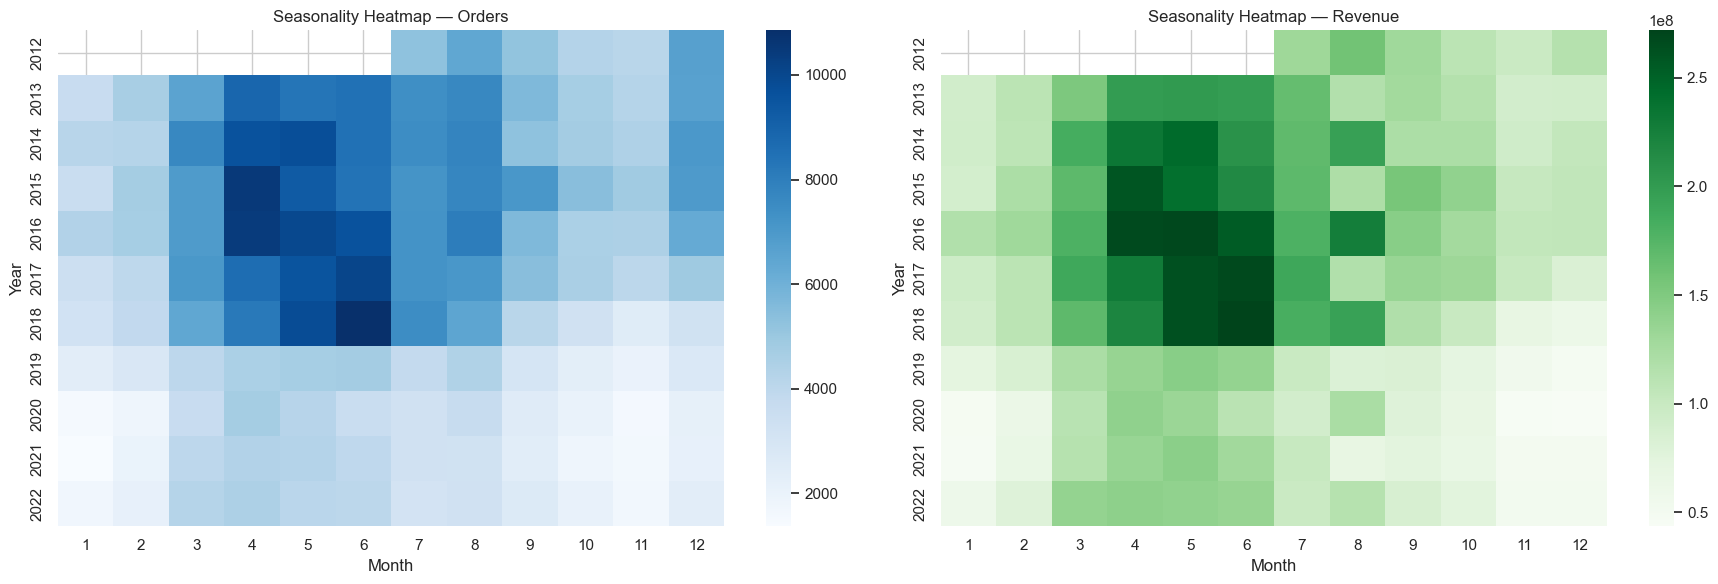

,month,avg_orders,avg_revenue,n_years,avg_orders_per_year,avg_revenue_per_year
3,4,"74,335","1,959,885,565",10,"7,434","195,988,556"
4,5,"73,943","2,038,379,068",10,"7,394","203,837,907"
5,6,"72,270","1,928,132,596",10,"7,227","192,813,260"
7,8,"65,811","1,514,446,980",11,"5,983","137,676,998"
2,3,"57,440","1,527,737,497",10,"5,744","152,773,750"
6,7,"62,776","1,575,008,809",11,"5,707","143,182,619"
11,12,"51,280","860,803,221",11,"4,662","78,254,838"
8,9,"49,054","1,253,282,449",11,"4,459","113,934,768"
9,10,"39,903","1,126,229,300",11,"3,628","102,384,482"
1,2,"35,031","981,585,819",10,"3,503","98,158,582"


In [50]:
seasonality = orders_enriched.groupby(["year", "month"], as_index=False).agg(
    orders=("order_id", "count"),
    revenue=("order_revenue", "sum")
)

heat_orders = seasonality.pivot(index="year", columns="month", values="orders")
heat_revenue = seasonality.pivot(index="year", columns="month", values="revenue")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.heatmap(heat_orders, cmap="Blues", annot=False, fmt=".0f", ax=axes[0])
axes[0].set_title("Seasonality Heatmap — Orders")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Year")

sns.heatmap(heat_revenue, cmap="Greens", annot=False, fmt=".0f", ax=axes[1])
axes[1].set_title("Seasonality Heatmap — Revenue")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Year")

plt.tight_layout()
plt.show()

month_avg = orders_enriched.groupby("month", as_index=False).agg(
    avg_orders=("order_id", "count"),
    avg_revenue=("order_revenue", "sum")
)
# Vì groupby count/sum trên toàn bộ giai đoạn, ta chuẩn hóa bằng số năm xuất hiện mỗi tháng
month_year_counts = orders_enriched.groupby("month")["year"].nunique().rename("n_years").reset_index()
month_avg = month_avg.merge(month_year_counts, on="month")
month_avg["avg_orders_per_year"] = month_avg["avg_orders"] / month_avg["n_years"]
month_avg["avg_revenue_per_year"] = month_avg["avg_revenue"] / month_avg["n_years"]

display(month_avg.sort_values("avg_orders_per_year", ascending=False).style.format({
    "avg_orders": "{:,.0f}",
    "avg_revenue": "{:,.0f}",
    "avg_orders_per_year": "{:,.0f}",
    "avg_revenue_per_year": "{:,.0f}"
}))

##### **Analysis 4 — Predictive/Prescriptive insight**

- Heatmap giúp xác định tháng cao điểm/thấp điểm theo lịch sử.
- Tháng có orders/revenue cao nên được chuẩn bị trước bằng:
  - ngân sách paid media,
  - tồn kho,
  - vận chuyển,
  - landing page,
  - chiến dịch remarketing.
- Tháng thấp điểm không nhất thiết phải giảm marketing, mà có thể dùng **promo có chọn lọc** để kích cầu nếu biên lợi nhuận còn đủ.

**Business implication:**  
Campaign calendar nên được lập theo mùa vụ, không chạy ngân sách đều quanh năm. Nếu tháng cao điểm bị thiếu tồn kho hoặc logistics quá tải, doanh nghiệp sẽ mất cơ hội tăng trưởng.

### Trả hàng do đâu

In [53]:
returns[returns["order_id"] ==702501    ]

,return_id,order_id,product_id,return_date,return_reason,return_quantity,refund_amount
33974,RET-043755,702501,548,2020-03-15,wrong_size,2,"11,916.9400"
33975,RET-043756,702501,1958,2020-03-16,wrong_size,3,"2,800.0600"
33976,RET-043757,702501,1959,2020-03-07,defective,4,"3,378.6000"


In [54]:
returns_copy = returns[["order_id","product_id","return_reason","refund_amount"]].copy()
returns_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39939 entries, 0 to 39938
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       39939 non-null  int64  
 1   product_id     39939 non-null  int64  
 2   return_reason  39939 non-null  object 
 3   refund_amount  39939 non-null  float64
dtypes: float64(1), int64(2), object(1)
memory usage: 1.2+ MB


In [55]:
returns_copy["return_reason"].unique()

array(['late_delivery', 'wrong_size', 'defective', 'changed_mind',
       'not_as_described'], dtype=object)

In [56]:
order_return_copy = orders[["order_id","order_date","customer_id"]].copy()
order_return_copy

,order_id,order_date,customer_id
0,1,2012-07-04,58578
1,2,2012-07-04,58621
2,3,2012-07-04,58811
3,4,2012-07-04,59453
4,6,2012-07-06,57821
...,...,...,...
646940,834372,2022-12-31,19490
646941,834377,2022-12-31,73046
646942,834387,2022-12-31,107723
646943,834392,2022-12-31,139431


In [57]:
product_return_copy = products[["product_id", "category", "product_name", "segment", "size", "color"]].copy()
product_return_copy

,product_id,category,product_name,segment,size,color
0,536,Streetwear,SaigonFlex UC-01,Everyday,S,green
1,537,Streetwear,SaigonFlex UC-02,Everyday,M,silver
2,538,Streetwear,SaigonFlex UC-03,Everyday,L,pink
3,539,Streetwear,SaigonFlex UC-04,Everyday,XL,yellow
4,540,Streetwear,SaigonFlex UC-05,Everyday,S,red
...,...,...,...,...,...,...
2407,1260,Casual,VietMode MP-28,Activewear,S,red
2408,1261,Casual,VietMode MP-29,Activewear,M,black
2409,1262,Casual,VietMode MP-30,Activewear,L,orange
2410,1263,Casual,VietMode MP-31,Activewear,XL,blue


In [58]:
return_reason = pd.merge(returns_copy, product_return_copy, on = "product_id", how = "inner")
return_reason = pd.merge(return_reason, order_return_copy, on = "order_id", how = "inner")
return_reason.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39939 entries, 0 to 39938
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       39939 non-null  int64         
 1   product_id     39939 non-null  int64         
 2   return_reason  39939 non-null  object        
 3   refund_amount  39939 non-null  float64       
 4   category       39939 non-null  object        
 5   product_name   39939 non-null  object        
 6   segment        39939 non-null  object        
 7   size           39939 non-null  object        
 8   color          39939 non-null  object        
 9   order_date     39939 non-null  datetime64[ns]
 10  customer_id    39939 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(6)
memory usage: 3.4+ MB


In [59]:
return_reason

,order_id,product_id,return_reason,refund_amount,category,product_name,segment,size,color,order_date,customer_id
0,2,609,late_delivery,"52,458.0100",Streetwear,SaigonFlex UC-74,Everyday,M,yellow,2012-07-04,58621
1,32,1862,wrong_size,"5,141.3700",GenZ,SaigonCore YY-57,Trendy,L,orange,2012-07-05,6037
2,35,2359,wrong_size,"5,315.9500",Streetwear,VietMotion UC-07,Everyday,XL,yellow,2012-07-04,3666
3,47,1449,wrong_size,"6,493.7500",Outdoor,VietMode RP-41,Activewear,M,yellow,2012-07-06,72063
4,47,1450,wrong_size,"1,740.7600",Outdoor,VietMode RP-42,Activewear,L,red,2012-07-06,72063
...,...,...,...,...,...,...,...,...,...,...,...
39934,832867,653,wrong_size,"24,741.6200",Streetwear,SaigonFlex UC-18,Everyday,M,blue,2022-12-18,147138
39935,832890,792,late_delivery,560.5000,Outdoor,HanoiStreet RP-80,Activewear,S,orange,2022-12-22,44182
39936,833005,449,defective,"10,002.5500",Streetwear,SaigonFlex UM-54,Balanced,M,yellow,2022-12-23,130667
39937,833234,1085,wrong_size,815.5700,Outdoor,MekongFit RP-31,Activewear,M,purple,2022-12-22,62347


### EDA các lí do trả hàng

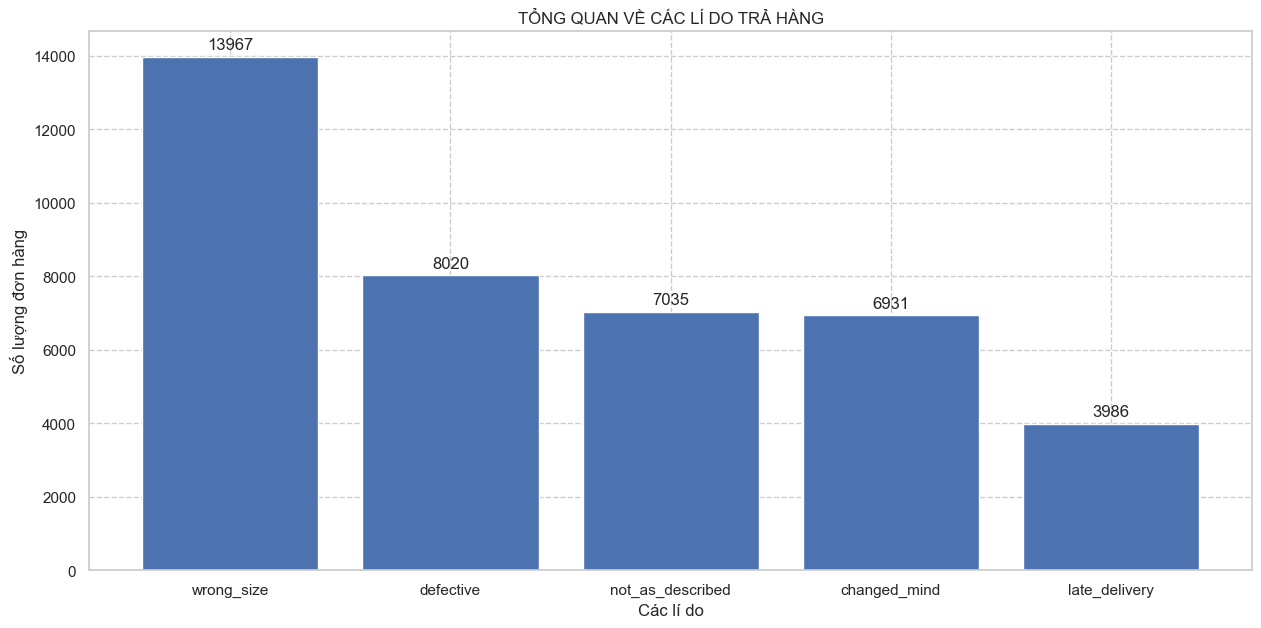

,return_reason,count
0,wrong_size,13967
1,defective,8020
2,not_as_described,7035
3,changed_mind,6931
4,late_delivery,3986


In [61]:
plt.figure(figsize=(15,7))
overViewReason = return_reason["return_reason"].value_counts().sort_values(ascending=False)
plt.bar(
    overViewReason.index,
    overViewReason.values
)
plt.title("TỔNG QUAN VỀ CÁC LÍ DO TRẢ HÀNG")
plt.grid(ls = "--")
for i in range(len(overViewReason)):
    plt.text(i, overViewReason[i] + 200,f"{overViewReason[i]}", horizontalalignment = "center" )
plt.xlabel("Các lí do")
plt.ylabel("Số lượng đơn hàng")
plt.show()
display(overViewReason.reset_index())

In [62]:
return_reason

,order_id,product_id,return_reason,refund_amount,category,product_name,segment,size,color,order_date,customer_id
0,2,609,late_delivery,"52,458.0100",Streetwear,SaigonFlex UC-74,Everyday,M,yellow,2012-07-04,58621
1,32,1862,wrong_size,"5,141.3700",GenZ,SaigonCore YY-57,Trendy,L,orange,2012-07-05,6037
2,35,2359,wrong_size,"5,315.9500",Streetwear,VietMotion UC-07,Everyday,XL,yellow,2012-07-04,3666
3,47,1449,wrong_size,"6,493.7500",Outdoor,VietMode RP-41,Activewear,M,yellow,2012-07-06,72063
4,47,1450,wrong_size,"1,740.7600",Outdoor,VietMode RP-42,Activewear,L,red,2012-07-06,72063
...,...,...,...,...,...,...,...,...,...,...,...
39934,832867,653,wrong_size,"24,741.6200",Streetwear,SaigonFlex UC-18,Everyday,M,blue,2022-12-18,147138
39935,832890,792,late_delivery,560.5000,Outdoor,HanoiStreet RP-80,Activewear,S,orange,2022-12-22,44182
39936,833005,449,defective,"10,002.5500",Streetwear,SaigonFlex UM-54,Balanced,M,yellow,2022-12-23,130667
39937,833234,1085,wrong_size,815.5700,Outdoor,MekongFit RP-31,Activewear,M,purple,2022-12-22,62347


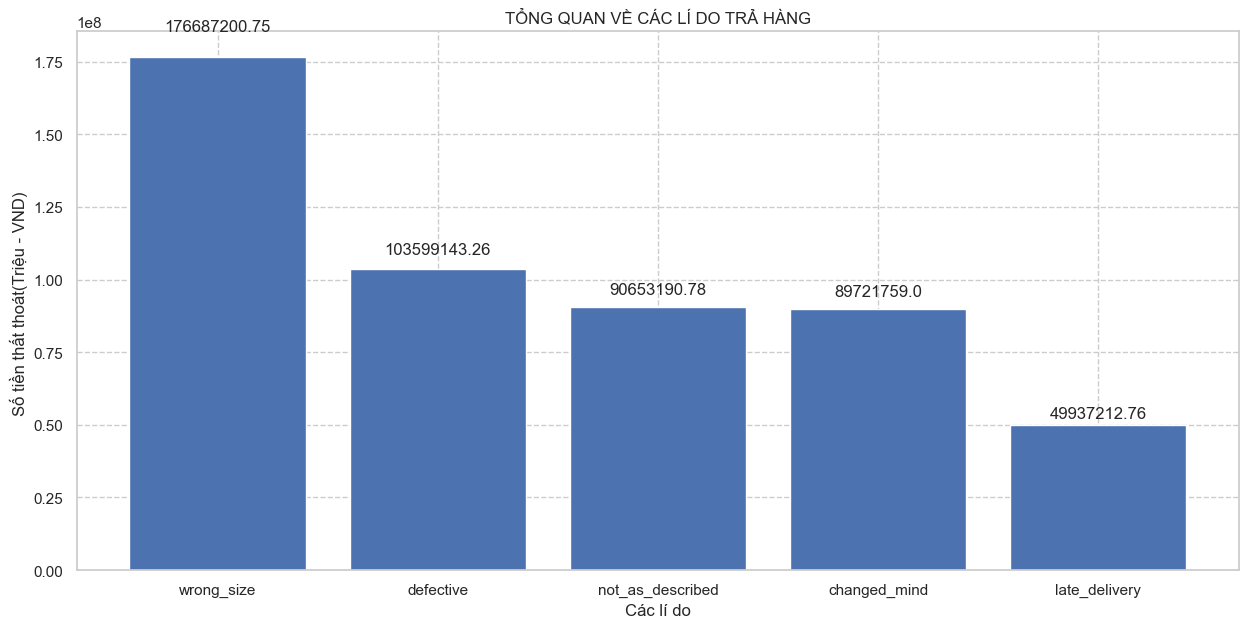

,return_reason,refund_amount
0,wrong_size,"176,687,200.7500"
1,defective,"103,599,143.2600"
2,not_as_described,"90,653,190.7800"
3,changed_mind,"89,721,759.0000"
4,late_delivery,"49,937,212.7600"


In [63]:
plt.figure(figsize=(15,7))
loss_by_return = return_reason.groupby("return_reason")["refund_amount"].sum().sort_values(ascending = False)
plt.bar(
    loss_by_return.index,
    loss_by_return.values
)
plt.title("TỔNG QUAN VỀ CÁC LÍ DO TRẢ HÀNG")
plt.grid(ls = "--")
for i in range(len(loss_by_return)):
    plt.text(i, loss_by_return[i] + loss_by_return[i]*0.05,f"{loss_by_return[i]}", horizontalalignment = "center" )
plt.xlabel("Các lí do")
plt.ylabel("Số tiền thất thoát(Triệu - VND) ")
plt.show()
display(loss_by_return.reset_index())

### Lí do là **`wrong_size`**

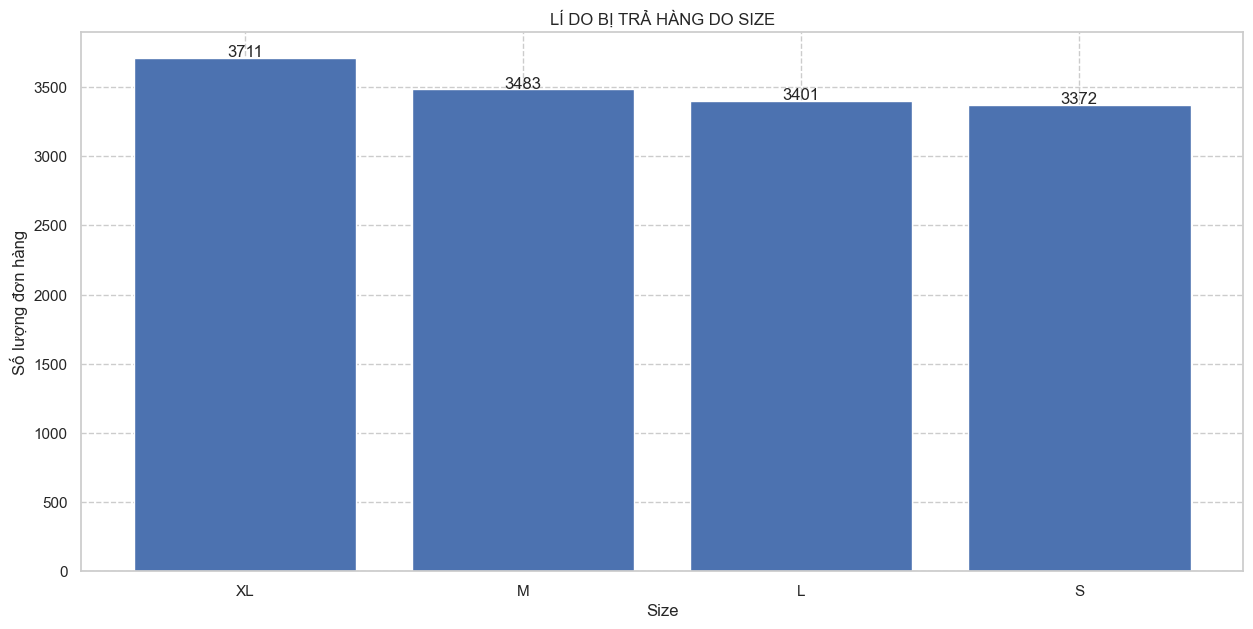

,size,count
0,XL,3711
1,M,3483
2,L,3401
3,S,3372


In [65]:
return_reason_wrong_size = return_reason[return_reason["return_reason"] == "wrong_size"]["size"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(15,7))
plt.bar(
    return_reason_wrong_size.index,
    return_reason_wrong_size.values
)
plt.title("LÍ DO BỊ TRẢ HÀNG DO SIZE")
plt.grid(ls = "--")
for i in range(len(return_reason_wrong_size)):
    plt.text(i, return_reason_wrong_size[i] + 10,f"{return_reason_wrong_size[i]}", horizontalalignment = "center" )
plt.xlabel("Size")
plt.ylabel("Số lượng đơn hàng")
plt.show()
display(return_reason_wrong_size.reset_index())

### Lí do là **`defective`**

In [67]:
return_reason_defective = return_reason[return_reason["return_reason"] == "defective"]

In [68]:
return_reason_defective

,order_id,product_id,return_reason,refund_amount,category,product_name,segment,size,color,order_date,customer_id
5,59,671,defective,"10,086.3300",Streetwear,SaigonFlex UC-36,Everyday,XL,black,2012-07-06,63551
7,102,467,defective,"9,724.0900",Streetwear,SaigonFlex UM-72,Balanced,XL,silver,2012-07-04,31661
16,305,2250,defective,"1,461.3900",Outdoor,VietMotion RP-47,Activewear,L,red,2012-07-05,33610
19,373,647,defective,"10,993.1600",Streetwear,SaigonFlex UC-12,Everyday,XL,silver,2012-07-07,143096
22,409,635,defective,"9,498.8400",Streetwear,SaigonFlex UC-00,Everyday,XL,purple,2012-07-08,44737
...,...,...,...,...,...,...,...,...,...,...,...
39918,832024,2225,defective,"2,706.5500",Outdoor,VietMotion RP-22,Activewear,M,purple,2022-12-12,120902
39922,832085,651,defective,"49,882.1900",Streetwear,SaigonFlex UC-16,Everyday,XL,black,2022-12-13,39752
39924,832170,1177,defective,"2,405.8500",Streetwear,MekongFit UE-13,Performance,M,silver,2022-12-12,123127
39933,832819,778,defective,"1,092.2900",Outdoor,HanoiStreet RP-66,Activewear,L,pink,2022-12-18,80350


In [69]:
return_reason_defective['category'].unique()

array(['Streetwear', 'Outdoor', 'GenZ', 'Casual'], dtype=object)

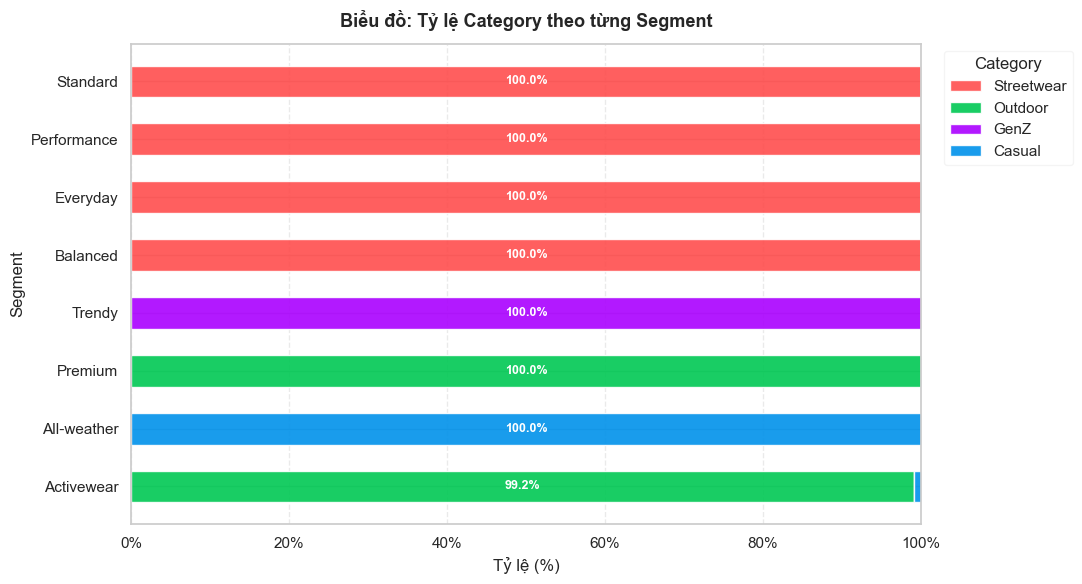

category,Streetwear,Outdoor,GenZ,Casual,totalreturn
segment,,,,,
Standard,102,0,0,0,102
All-weather,0,0,0,240,240
Premium,0,346,0,0,346
Trendy,0,0,429,0,429
Performance,1055,0,0,0,1055
Balanced,1143,0,0,0,1143
Everyday,2030,0,0,0,2030
Activewear,0,2653,0,22,2675


In [70]:
category = ['Streetwear', 'Outdoor', 'GenZ', 'Casual']

category_COLORS = {
    'Streetwear': '#FF4D4D',
    'Outdoor': '#00C853',
    'GenZ': '#AA00FF',
    'Casual': '#0091EA'
}

# Lọc dữ liệu
dfcategory_return = return_reason_defective[
    return_reason_defective['category'].isin(category)
].copy()

# Pivot table
pivot_category = (
    dfcategory_return
    .groupby(['segment', 'category'])['order_id']
    .count()
    .unstack(fill_value=0)
)

# Đảm bảo đủ cột category
for c in category:
    if c not in pivot_category.columns:
        pivot_category[c] = 0

pivot_category = pivot_category[category]

# Chuyển sang %
pivot_category_pct = (
    pivot_category
    .div(pivot_category.sum(axis=1), axis=0) * 100
)

# Sắp xếp theo Streetwear
pivot_category_pct = pivot_category_pct.sort_values(
    'Streetwear',
    ascending=True
)

# =========================
# VẼ BIỂU ĐỒ
# =========================
fig, ax = plt.subplots(figsize=(11, 6))

bottom = np.zeros(len(pivot_category_pct))

for c in category:
    vals = pivot_category_pct[c].values

    ax.barh(
        pivot_category_pct.index,
        vals,
        left=bottom,
        label=c,
        color=category_COLORS[c],
        alpha=0.9,
        height=0.55
    )

    # Hiển thị %
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 3:
            ax.text(
                b + v/2,
                i,
                f'{v:.1f}%',
                ha='center',
                va='center',
                fontsize=9,
                color='white',
                fontweight='bold'
            )

    bottom += vals

# =========================
# FORMAT
# =========================
ax.set_xlim(0, 100)

ax.set_xlabel('Tỷ lệ (%)', fontsize=12)
ax.set_ylabel('Segment', fontsize=12)

ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{int(x)}%')
)

ax.grid(axis='x', linestyle='--', alpha=0.4)

ax.legend(
    title='Category',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    framealpha=0.2
)

plt.title(
    'Biểu đồ: Tỷ lệ Category theo từng Segment',
    fontsize=13,
    fontweight='bold',
    pad=12
)

plt.tight_layout()
plt.show()
# Thêm cột tổng theo chiều ngang
pivot_category['totalreturn'] = pivot_category.sum(axis=1)
display(pivot_category.sort_values(by ="totalreturn"))

In [71]:
return_reason_not_as_described = return_reason[return_reason["return_reason"] == "not_as_described"]
return_reason_not_as_described["color"].value_counts()

color
purple    946
green     820
orange    813
white     790
silver    678
yellow    646
blue      634
black     633
red       568
pink      507
Name: count, dtype: int64

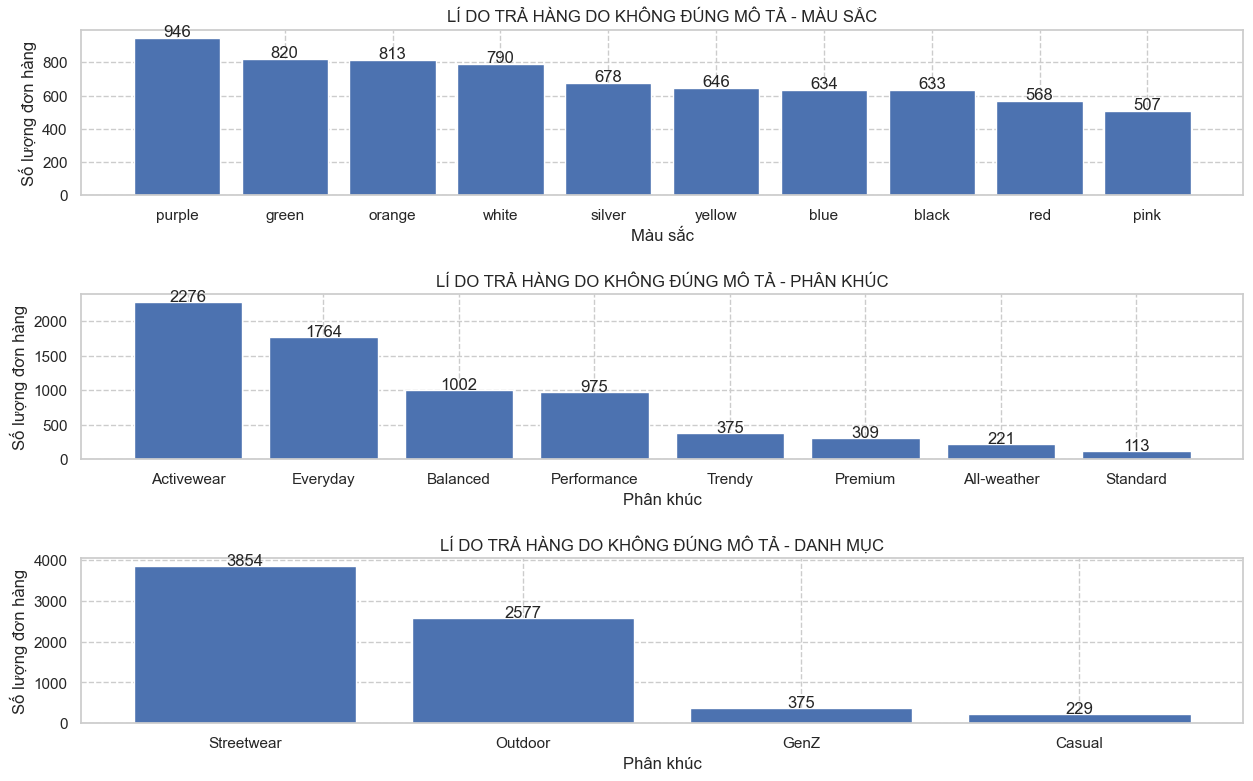

Trả hàng không đúng mô tả - Màu sắc


,color,count
0,purple,946
1,green,820
2,orange,813
3,white,790
4,silver,678
5,yellow,646
6,blue,634
7,black,633
8,red,568
9,pink,507


Trả hàng không đúng mô tả - Phân khúc


,segment,count
0,Activewear,2276
1,Everyday,1764
2,Balanced,1002
3,Performance,975
4,Trendy,375
5,Premium,309
6,All-weather,221
7,Standard,113


Trả hàng không đúng mô tả - Phân loại


,category,count
0,Streetwear,3854
1,Outdoor,2577
2,GenZ,375
3,Casual,229


In [72]:
return_reason_not_as_described_color = return_reason[return_reason["return_reason"] == "not_as_described"]["color"].value_counts().sort_values(ascending=False)
return_reason_not_as_described_segment = return_reason[return_reason["return_reason"] == "not_as_described"]["segment"].value_counts().sort_values(ascending=False)
return_reason_not_as_described_category = return_reason[return_reason["return_reason"] == "not_as_described"]["category"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(15,9))

plt.subplot(3,1,1)
plt.bar(
    return_reason_not_as_described_color.index,
    return_reason_not_as_described_color.values
)
plt.title("LÍ DO TRẢ HÀNG DO KHÔNG ĐÚNG MÔ TẢ - MÀU SẮC")
plt.grid(ls = "--")
for i in range(len(return_reason_not_as_described_color)):
    plt.text(i, return_reason_not_as_described_color[i] + 10,f"{return_reason_not_as_described_color[i]}", horizontalalignment = "center" )
plt.xlabel("Màu sắc")
plt.ylabel("Số lượng đơn hàng")

plt.subplot(3,1,2)
plt.bar(
    return_reason_not_as_described_segment.index,
    return_reason_not_as_described_segment.values
)
plt.title("LÍ DO TRẢ HÀNG DO KHÔNG ĐÚNG MÔ TẢ - PHÂN KHÚC")
plt.grid(ls = "--")
for i in range(len(return_reason_not_as_described_segment)):
    plt.text(i, return_reason_not_as_described_segment[i] + 10,f"{return_reason_not_as_described_segment[i]}", horizontalalignment = "center" )
plt.xlabel("Phân khúc")
plt.ylabel("Số lượng đơn hàng")

plt.subplot(3,1,3)
plt.bar(
    return_reason_not_as_described_category.index,
    return_reason_not_as_described_category.values
)
plt.title("LÍ DO TRẢ HÀNG DO KHÔNG ĐÚNG MÔ TẢ - DANH MỤC")
plt.grid(ls = "--")
for i in range(len(return_reason_not_as_described_category)):
    plt.text(i, return_reason_not_as_described_category[i] + 10,f"{return_reason_not_as_described_category[i]}", horizontalalignment = "center" )
plt.xlabel("Phân khúc")
plt.ylabel("Số lượng đơn hàng")
plt.subplots_adjust(hspace=0.6)
plt.show()
print("Trả hàng không đúng mô tả - Màu sắc")
display(return_reason_not_as_described_color.reset_index())

print("Trả hàng không đúng mô tả - Phân khúc")
display(return_reason_not_as_described_segment.reset_index())

print("Trả hàng không đúng mô tả - Phân loại")
display(return_reason_not_as_described_category.reset_index())


### Lí do là **`changed_mind`**

In [74]:
dfgeo_copy = geo[["zip", "region"]].copy()
dfcus_copy = customers[["customer_id","zip","gender", "age_group"]].copy()

In [75]:
return_reason

,order_id,product_id,return_reason,refund_amount,category,product_name,segment,size,color,order_date,customer_id
0,2,609,late_delivery,"52,458.0100",Streetwear,SaigonFlex UC-74,Everyday,M,yellow,2012-07-04,58621
1,32,1862,wrong_size,"5,141.3700",GenZ,SaigonCore YY-57,Trendy,L,orange,2012-07-05,6037
2,35,2359,wrong_size,"5,315.9500",Streetwear,VietMotion UC-07,Everyday,XL,yellow,2012-07-04,3666
3,47,1449,wrong_size,"6,493.7500",Outdoor,VietMode RP-41,Activewear,M,yellow,2012-07-06,72063
4,47,1450,wrong_size,"1,740.7600",Outdoor,VietMode RP-42,Activewear,L,red,2012-07-06,72063
...,...,...,...,...,...,...,...,...,...,...,...
39934,832867,653,wrong_size,"24,741.6200",Streetwear,SaigonFlex UC-18,Everyday,M,blue,2022-12-18,147138
39935,832890,792,late_delivery,560.5000,Outdoor,HanoiStreet RP-80,Activewear,S,orange,2022-12-22,44182
39936,833005,449,defective,"10,002.5500",Streetwear,SaigonFlex UM-54,Balanced,M,yellow,2022-12-23,130667
39937,833234,1085,wrong_size,815.5700,Outdoor,MekongFit RP-31,Activewear,M,purple,2022-12-22,62347


In [76]:
return_reason = pd.merge(return_reason, dfcus_copy, on = "customer_id", how = "inner")
return_reason = pd.merge(return_reason, dfgeo_copy, on = "zip", how = "inner")

In [77]:
df_changed = return_reason[
    return_reason['return_reason'] == 'changed_mind'
].copy()

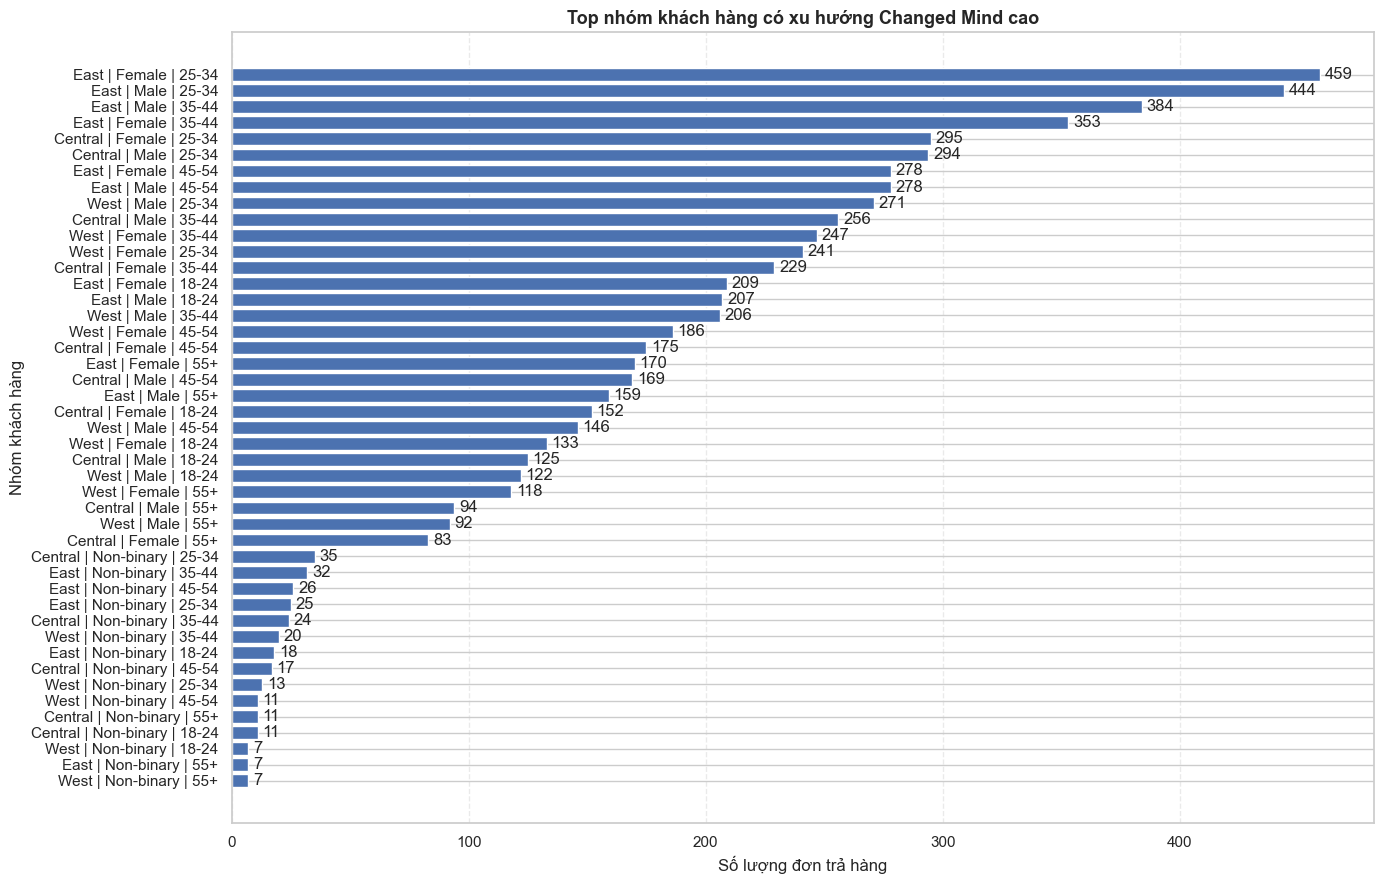

In [78]:
changed_profile = (
    df_changed
    .groupby(['region', 'gender', 'age_group'])['order_id']
    .nunique()
    .reset_index(name='total_orders')
    .sort_values('total_orders', ascending=False)
)
top10 = changed_profile

labels = (
    top10['region']
    + ' | '
    + top10['gender']
    + ' | '
    + top10['age_group']
)

plt.figure(figsize=(14,9))

bars = plt.barh(
    labels[::-1],
    top10['total_orders'][::-1],
    # height=0.4

)

plt.title(
    "Top nhóm khách hàng có xu hướng Changed Mind cao",
    fontsize=13,
    fontweight='bold'
)

plt.xlabel("Số lượng đơn trả hàng")
plt.ylabel("Nhóm khách hàng")

plt.grid(axis='x', linestyle='--', alpha=0.4)

for i, v in enumerate(top10['total_orders'][::-1]):
    plt.text(v + 2, i, str(v), va='center')

plt.tight_layout()
plt.show()

### Lí do là **`late_delivery`**

In [80]:
late_delivery = return_reason[
    return_reason['return_reason'] == 'late_delivery'
]

In [81]:
shipments_returns =  shipments[["order_id","ship_date","delivery_date"]].copy()
late_delivery = pd.merge(shipments_returns, late_delivery, on = "order_id", how = "inner")
late_delivery.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3986 entries, 0 to 3985
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       3986 non-null   int64         
 1   ship_date      3986 non-null   datetime64[ns]
 2   delivery_date  3986 non-null   datetime64[ns]
 3   product_id     3986 non-null   int64         
 4   return_reason  3986 non-null   object        
 5   refund_amount  3986 non-null   float64       
 6   category       3986 non-null   object        
 7   product_name   3986 non-null   object        
 8   segment        3986 non-null   object        
 9   size           3986 non-null   object        
 10  color          3986 non-null   object        
 11  order_date     3986 non-null   datetime64[ns]
 12  customer_id    3986 non-null   int64         
 13  zip            3986 non-null   int64         
 14  gender         3986 non-null   object        
 15  age_group      3986 n

In [82]:
late_delivery["shipToDelivery"] = (late_delivery['delivery_date'] - late_delivery['ship_date']).dt.days
late_delivery["orderToDelivery"]   = (late_delivery['delivery_date'] - late_delivery['order_date']).dt.days

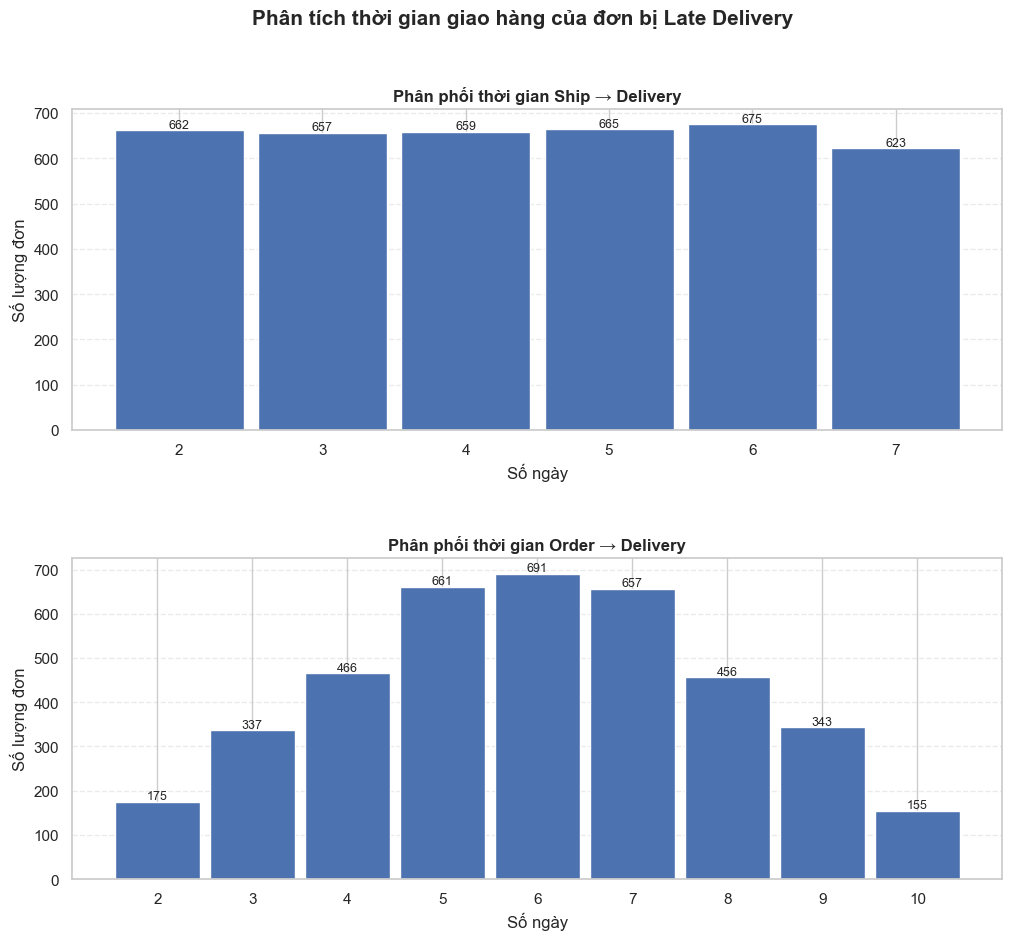

In [85]:
df_late_order = (
    late_delivery
    .groupby('order_id')
    .agg({
        'shipToDelivery': 'first',
        'orderToDelivery': 'first'
    })
    .reset_index()
)
ship_counts = (
    df_late_order['shipToDelivery']
    .value_counts()
    .sort_index()
)

order_counts = (
    df_late_order['orderToDelivery']
    .value_counts()
    .sort_index()
)

# =========================
# VẼ BIỂU ĐỒ
# =========================

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# ------------------------------------------------
# 1. SHIP -> DELIVERY
# ------------------------------------------------

axes[0].bar(
    ship_counts.index,
    ship_counts.values,
    width=0.9
)

axes[0].set_title(
    'Phân phối thời gian Ship → Delivery',
    fontsize=12,
    fontweight='bold'
)

axes[0].set_xlabel('Số ngày')
axes[0].set_ylabel('Số lượng đơn')

axes[0].set_xticks(ship_counts.index)

axes[0].grid(axis='y', linestyle='--', alpha=0.4)

# Hiển thị số trên đầu cột
for i, v in zip(ship_counts.index, ship_counts.values):
    axes[0].text(
        i,
        v + 5,
        str(v),
        ha='center',
        fontsize=9
    )

# ------------------------------------------------
# 2. ORDER -> DELIVERY
# ------------------------------------------------

axes[1].bar(
    order_counts.index,
    order_counts.values,
    width=0.9
)

axes[1].set_title(
    'Phân phối thời gian Order → Delivery',
    fontsize=12,
    fontweight='bold'
)

axes[1].set_xlabel('Số ngày')
axes[1].set_ylabel('Số lượng đơn')

axes[1].set_xticks(order_counts.index)

axes[1].grid(axis='y', linestyle='--', alpha=0.4)

# Hiển thị số trên đầu cột
for i, v in zip(order_counts.index, order_counts.values):
    axes[1].text(
        i,
        v + 5,
        str(v),
        ha='center',
        fontsize=9
    )

# =========================
# FORMAT
# =========================

plt.suptitle(
    'Phân tích thời gian giao hàng của đơn bị Late Delivery',
    fontsize=15,
    fontweight='bold'
)

plt.subplots_adjust(hspace=0.4)

plt.show()